# Лабораторная работа №4
# Выполнил студент группы МОАм-251 Козырев А.Д.

Довожу модель ранжирования рекомендаций (сценарий ЛР-1 и ЛР-3) от прототипа до production-контура: выбор модели с логированием в MLflow, Feature Store на Feast с проверкой согласованности фич, инференс-сервис на FastAPI с canary и откатом, мониторинг дрейфа, сравнение пакетного и онлайн-обучения и обработка холодного старта (уникальное требование варианта 5). Отдельная часть - прогноз температуры сенсора с автоотключением.

In [39]:
import importlib.util, subprocess, sys, os
_need = {'mlflow': 'mlflow', 'feast': 'feast', 'evidently': 'evidently', 'river': 'river', 'lightgbm': 'lightgbm',
         'fastapi': 'fastapi', 'uvicorn': 'uvicorn', 'httpx': 'httpx', 'duckdb': 'duckdb', 'kagglehub': 'kagglehub',
         'psutil': 'psutil', 'pytest': 'pytest'}
_missing = [pkg for mod, pkg in _need.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], check=True)

os.makedirs('work', exist_ok=True)
os.environ['MLFLOW_DISABLE_AGENT_HINT'] = '1'
os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'false'
os.environ['GIT_PYTHON_REFRESH'] = 'quiet'
os.environ['FEAST_USAGE'] = 'False'
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import glob, json, shutil, time, socket, threading, logging, warnings, hashlib, urllib.request
from datetime import date, datetime, timedelta
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import duckdb
import mlflow
import feast
import lightgbm
import river
import sklearn
from sklearn.metrics import roc_auc_score, roc_curve
from IPython.display import display, HTML, Image

warnings.filterwarnings('ignore')
for name in ('mlflow', 'feast', 'alembic', 'urllib3', 'httpx', 'evidently'):
    logging.getLogger(name).setLevel(logging.ERROR)

SEED = 42
np.random.seed(SEED)
N_CORES = os.cpu_count()
RAM_GB = psutil.virtual_memory().total / 2**30
N_JOBS = max(1, min(4, N_CORES))

CSV = '2019-Oct.csv'
DATA = 'work/data'
REPO = 'feature_repo'
START, N_DAYS = '2019-10-01', 9                  # события 1-9 октября
TRAIN_DAYS, VAL_DAY, TEST_DAY, NEXT_DAY = ['2019-10-05', '2019-10-06'], '2019-10-07', '2019-10-08', '2019-10-09'
PRICE = {'vm_vcpu_hour': 1.24, 'vm_ram_gb_hour': 0.33}   # Yandex Compute Cloud, как в ЛР-1 - ЛР-3

COLORS = ['#2a78d6', '#1baf7a', '#eb6834', '#4a3aa7', '#eda100', '#e34948', '#8a8984']
plt.rcParams.update({
    'figure.figsize': (10, 4.2), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b4ad',
    'axes.grid': True, 'grid.color': '#e6e5df', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'lines.linewidth': 2, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'legend.frameon': False,
})
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
display(pd.DataFrame([('CPU, логических ядер', N_CORES), ('RAM, ГБ', round(RAM_GB, 1)), ('Python', sys.version.split()[0]),
                      ('MLflow', mlflow.__version__), ('Feast', feast.__version__), ('LightGBM', lightgbm.__version__),
                      ('River', river.__version__), ('scikit-learn', sklearn.__version__), ('pandas', pd.__version__)],
                     columns=['Компонент', 'Значение']))

,Компонент,Значение
0,"CPU, логических ядер",2
1,"RAM, ГБ",12.7
2,Python,3.13.18
3,MLflow,3.18.0
4,Feast,0.68.0
5,LightGBM,4.6.0
6,River,0.26.1
7,scikit-learn,1.6.1
8,pandas,2.2.3


## Вариант, данные и бизнес-сценарий

Вариант 5: **E-commerce Clickstream** (`2019-Oct.csv`, Kaggle mkechinov, 42,4 млн событий октября 2019). Бизнес-сценарий: **2. Рекомендательная система**. Требования: latency < 100 мс для инференса, увеличение CTR на 10%, согласованность фич в offline/online. Уникальное требование для последней цифры 5: **реализовать обработку холодных стартеров**.

Модель ЛР-1 и ЛР-3 («популярное в категории») одинакова для всех пользователей. Здесь к ней добавляется персональный ранжировщик: из кандидатов он выбирает товары, с которыми пользователь вероятнее всего будет взаимодействовать. Для обучения берутся события 1-9 октября. Чтобы обучение и мониторинг шли на одном сервере без кластера, пользовательские данные взяты по выборке: пользователи с `user_id % 20 = 0` (5%). Выборка детерминированная, без случайности. Статистики товаров считаются по всем событиям.

In [40]:
import os, kagglehub
CSV = '2019-Oct.csv'
if not os.path.exists(CSV):
    p = kagglehub.dataset_download('mkechinov/ecommerce-behavior-data-from-multi-category-store', path=CSV)
    if os.path.isdir(p):
        p = os.path.join(p, CSV)
    print('Файл датасета:', p)
    os.symlink(p, CSV)
print(os.path.exists(CSV), os.path.getsize(CSV) / 2**30, 'ГБ')

True 5.279307118616998 ГБ


In [41]:
if not os.path.exists(CSV):
    import kagglehub
    kagglehub.dataset_download('mkechinov/ecommerce-behavior-data-from-multi-category-store',
                               path='2019-Oct.csv', output_dir='.')
    shutil.rmtree('.complete', ignore_errors=True)
from training import data as D
if not os.path.exists(f'{DATA}/events_sample.parquet'):
    D.build_base(CSV, DATA, START, N_DAYS, mem_mb=int(RAM_GB * 0.25 * 1024), threads=min(4, N_CORES))
ev = pd.read_parquet(f'{DATA}/events_sample.parquet')
print(f'Событий выбранных пользователей: {len(ev):,}, пользователей: {ev.user_id.nunique():,}'.replace(',', ' '))
display(ev.groupby(ev.event_time.dt.date).event_type.value_counts().unstack().fillna(0).astype(int))

Событий выбранных пользователей: 571 538  пользователей: 59 875


event_type,cart,purchase,view
event_time,,,
2019-10-01,731,961,59650
2019-10-02,826,958,57627
2019-10-03,1076,967,54092
2019-10-04,2199,1291,66540
2019-10-05,1831,1171,61193
2019-10-06,1697,1081,63072
2019-10-07,952,1022,58903
2019-10-08,856,1138,65473
2019-10-09,825,1116,64290


## Часть 1: Прототипирование и выбор модели

### 1) Выполните первичный анализ данных:

**Определите тип задачи (классификация, регрессия, кластеризация).** Бинарная классификация. Объект - пара «сессия, товар», которую пользователь просмотрел; метка 1, если в той же сессии этот товар добавлен в корзину или куплен. Вероятность метки - оценка того, что пользователь заинтересуется товаром (аналог CTR). По ней ранжируются кандидаты в рекомендации.

Признаки (все на начало дня по окну 7 дней, без данных самого дня):
- пользователь: просмотры, корзины, покупки, сессии, активные дни, средняя цена просмотренного, доли корзин и покупок;
- товар: просмотры, корзины, покупки, пользователи, средняя цена, сглаженные доли корзин и покупок (по всем пользователям);
- запрос: цена товара в момент просмотра, час, отношение цены к средней цене товара.

Обучение на 5-6 октября, валидация (выбор порога) на 7-м, тест на 8-м. Деление по времени, как в production: модель видит только прошлое.

In [42]:
SNAP_DAYS = D.days('2019-10-02', N_DAYS)            # снимки на начало 2-10 октября
os.makedirs(f'{REPO}/data', exist_ok=True)
if not os.path.exists(f'{REPO}/data/user_stats.parquet'):
    us, ps = D.build_snapshots(DATA, SNAP_DAYS)
    us.to_parquet(f'{REPO}/data/user_stats.parquet', index=False)
    ps.to_parquet(f'{REPO}/data/product_stats.parquet', index=False)
user_stats = pd.read_parquet(f'{REPO}/data/user_stats.parquet')
product_stats = pd.read_parquet(f'{REPO}/data/product_stats.parquet')

def direct_join(pairs):
    """Прототип: point-in-time join снимков вручную (снимок на начало дня события)."""
    p = pairs.copy()
    p['snap'] = p['event_timestamp'].dt.normalize()
    p = p.merge(user_stats.drop(columns='created').rename(columns={'event_timestamp': 'snap'}), on=['user_id', 'snap'], how='left')
    p = p.merge(product_stats.drop(columns='created').rename(columns={'event_timestamp': 'snap'}), on=['product_id', 'snap'], how='left')
    return D.add_request_features(p.drop(columns='snap'))

pairs = {d: D.build_pairs(DATA, [d]) for d in TRAIN_DAYS + [VAL_DAY, TEST_DAY, NEXT_DAY]}
proto = {d: direct_join(p) for d, p in pairs.items()}
eda = pd.concat([proto[d].assign(day=d) for d in proto])
summary = eda.groupby('day').agg(pairs=('label', 'size'), positive_rate=('label', 'mean'),
                                 users=('user_id', 'nunique'), cold_share=('u_views_7d', lambda s: s.isna().mean()))
display(summary.round(4))

,pairs,positive_rate,users,cold_share
day,,,,
2019-10-05,41663,0.0409,9610,0.5517
2019-10-06,42659,0.0376,9756,0.5264
2019-10-07,40450,0.0305,9343,0.5015
2019-10-08,45116,0.0293,10942,0.5045
2019-10-09,44738,0.0283,10579,0.4844


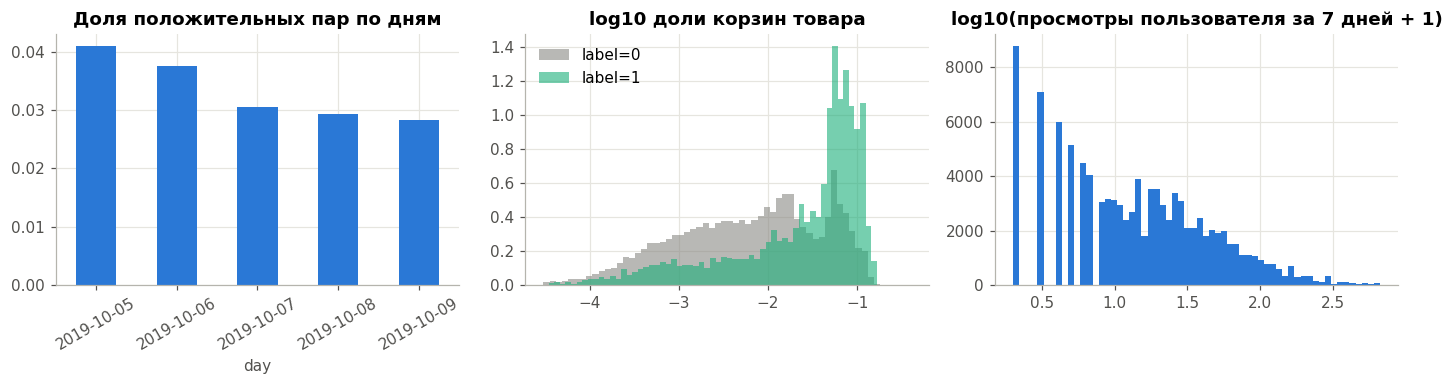

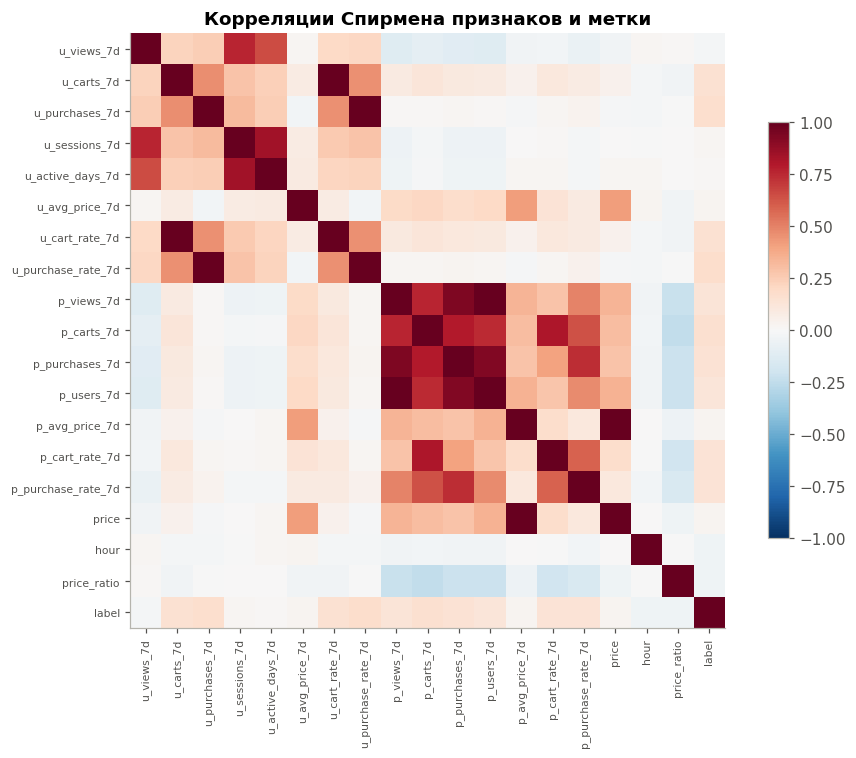

,corr с меткой
u_purchase_rate_7d,0.174
u_purchases_7d,0.166
p_carts_7d,0.157
u_cart_rate_7d,0.155
u_carts_7d,0.149
p_purchases_7d,0.141
p_purchase_rate_7d,0.139
p_cart_rate_7d,0.136
p_views_7d,0.126
p_users_7d,0.122


,"пропуски, %",асимметрия (skew),p99 / медиана
u_views_7d,51.33,5.48,21.00
u_carts_7d,51.33,9.87,NaN
u_purchases_7d,51.33,7.86,NaN
u_sessions_7d,51.33,3.66,11.50
u_active_days_7d,51.33,1.43,3.00
u_avg_price_7d,51.33,2.01,6.85
u_cart_rate_7d,51.33,34.82,NaN
u_purchase_rate_7d,51.33,5.51,NaN
p_views_7d,0.93,3.98,131.77
p_carts_7d,0.93,5.11,NaN


Пользователей выборки с > 1000 событий за 9 дней: 0, у них 0.0% событий


In [43]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
summary['positive_rate'].plot.bar(ax=ax[0], color=COLORS[0], rot=30)
ax[0].set_title('Доля положительных пар по дням')
for lab, c in ((0, COLORS[6]), (1, COLORS[1])):
    v = np.log10(eda.loc[eda.label == lab, 'p_cart_rate_7d'].dropna())
    ax[1].hist(v, bins=60, alpha=0.6, color=c, density=True, label=f'label={lab}')
ax[1].set_title('log10 доли корзин товара'); ax[1].legend()
ax[2].hist(np.log10(eda['u_views_7d'].dropna() + 1), bins=60, color=COLORS[0])
ax[2].set_title('log10(просмотры пользователя за 7 дней + 1)')
plt.tight_layout(); plt.show()

corr = eda[D.FEATURES + ['label']].corr(method='spearman')
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=7)
plt.colorbar(im, ax=ax, shrink=0.7); ax.set_title('Корреляции Спирмена признаков и метки'); ax.grid(False)
plt.tight_layout(); plt.show()
display(corr['label'].drop('label').sort_values(key=abs, ascending=False).round(3).to_frame('corr с меткой'))

problems = pd.DataFrame({
    'пропуски, %': eda[D.FEATURES].isna().mean() * 100,
    'асимметрия (skew)': eda[D.FEATURES].skew(),
    'p99 / медиана': eda[D.FEATURES].quantile(0.99) / eda[D.FEATURES].median().replace(0, np.nan)}).round(2)
display(problems)
bots = ev.groupby('user_id').size()
print(f'Пользователей выборки с > 1000 событий за 9 дней: {(bots > 1000).sum()}, '
      f'у них {bots[bots > 1000].sum() / bots.sum():.1%} событий')

**Выявите проблемы с данными (пропуски, skew, шум).** Пропуски: у 51,3% пар пустые пользовательские фичи (в тестовом дне 50,4%): у пользователя нет событий за предыдущие 7 дней, то есть это холодный старт, а не сбой выгрузки; у товарных фич пропусков 0,9% (новые товары без истории); фичи запроса полные. Асимметрия: тяжёлые правые хвосты: skew у `u_cart_rate_7d` 34,8, у `price_ratio` 84,0, у `u_carts_7d` 9,9, у `u_purchases_7d` 7,9; p99 / медиана у `p_purchases_7d` 715, у `p_views_7d` 132. Линейной модели нужны масштабирование и логарифмирование, деревьям нет. Дисбаланс: положительных пар 2,8-4,1%, и доля снижается с 5 по 9 октября (4,09% → 2,83%), поэтому помимо AUC считаются PR-AUC и F1 с порогом с валидации. Шум и боты: пользователей с > 1000 событий за 9 дней в выборке нет, фильтровать выбросы по активности не нужно. Связь с меткой слабая и распределённая: максимум корреляции 0,174 (`u_purchase_rate_7d`), ни один признак сам задачу не решает.

### 2) Сравните несколько моделей:

Четыре модели на одном наборе признаков: логистическая регрессия (линейный baseline), случайный лес, HistGradientBoosting и LightGBM. Метрики на тестовом дне: AUC (качество ранжирования, главная), PR-AUC (классы несбалансированы), F1 при пороге, выбранном на валидации, log loss, время обучения и задержка предсказания одной строки. Каждый запуск логируется в MLflow (эксперимент `reco-ranker-selection`).

,auc,pr_auc,log_loss,f1,positive_rate_pred,p50_ms,p95_ms,p99_ms,fit_seconds,threshold
model,,,,,,,,,,
lightgbm,0.7795,0.1819,0.1144,0.2341,0.0217,1.3018,2.7079,4.8481,7.2035,0.1706
random_forest,0.7790,0.1931,0.1143,0.2444,0.0291,36.7530,39.7011,46.1240,9.9084,0.1443
hist_gradient_boosting,0.7766,0.1820,0.1147,0.2337,0.0252,2.3043,3.3270,3.9720,1.9439,0.1526
logreg,0.7665,0.1576,0.1169,0.2181,0.0221,1.8547,2.7598,3.3281,1.1031,0.1487


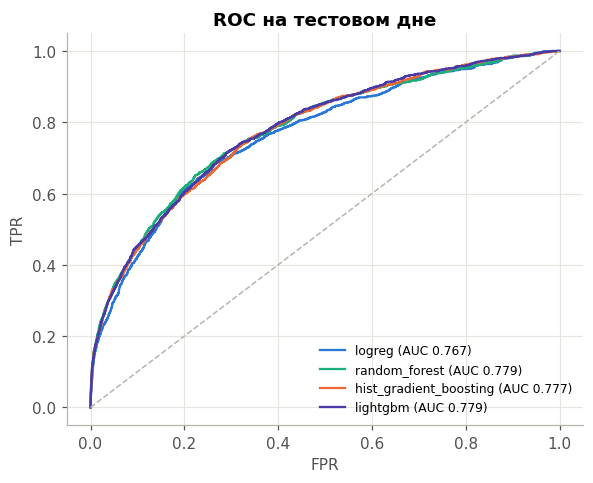

Эвристика без обучения (доля корзин товара за 7 дней): AUC 0.7008


In [44]:
MLFLOW_DB = os.path.abspath('work/mlflow.db')
MLFLOW_ART = os.path.abspath('work/mlartifacts')
mlflow.set_tracking_uri(f'sqlite:///{MLFLOW_DB}')
from training import batch_training as BT

train = pd.concat([proto[d] for d in TRAIN_DAYS], ignore_index=True)
val, test = proto[VAL_DAY], proto[TEST_DAY]
FEATS = D.FEATURES
if mlflow.get_experiment_by_name('reco-ranker-selection') is None:
    mlflow.create_experiment('reco-ranker-selection', artifact_location=f'file://{MLFLOW_ART}/selection')
sel_rows = []
for name, model in BT.make_models(SEED, N_JOBS).items():
    sel_rows.append(BT.train_and_log(name, model, train, val, test, FEATS, 'reco-ranker-selection',
                                     tags={'stage': 'prototype'}))
    sel_rows[-1]['_model'] = model
selection = pd.DataFrame(sel_rows).set_index('model')
display(selection.drop(columns=['_model', 'run_id']).round(4).sort_values('auc', ascending=False))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for (name, r), c in zip(selection.iterrows(), COLORS):
    fpr, tpr, _ = roc_curve(test['label'], r['_model'].predict_proba(test[FEATS])[:, 1])
    ax.plot(fpr, tpr, color=c, lw=1.5, label=f"{name} (AUC {r['auc']:.3f})")
ax.plot([0, 1], [0, 1], ls='--', color='#b5b4ad', lw=1)
ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.set_title('ROC на тестовом дне'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
BASELINE_AUC = roc_auc_score(test['label'], test['p_cart_rate_7d'].fillna(test['p_cart_rate_7d'].median()))
print(f'Эвристика без обучения (доля корзин товара за 7 дней): AUC {BASELINE_AUC:.4f}')

**Выберите лучшую модель для дальнейшей работы.** LightGBM: AUC 0,7795 на тестовом дне против 0,7790 у случайного леса, 0,7766 у HistGradientBoosting и 0,7665 у логистической регрессии; эвристика «доля корзин товара» даёт 0,7008. Разница между тремя ансамблями (0,0005-0,003) на одном разбиении мала, поэтому решает цена в production: p99 предсказания одной строки у LightGBM 4,8 мс, у случайного леса 46,1 мс (в 10 раз больше и почти на пороге 50 мс), хотя PR-AUC и F1 у леса чуть выше (0,193 и 0,244 против 0,182 и 0,234). HistGradientBoosting учится быстрее (около 2 с против 4-7 с), но уступает по AUC. LightGBM ранжирует не хуже лучшей модели, укладывается в бюджет задержки и сам обрабатывает пропуски холодных пользователей.

### 3) Реализуйте базовый пайплайн:

Базовый пайплайн повторяет пример задания: `Pipeline` из импутации, масштабирования и классификатора (код в `training/batch_training.py`, `make_models`). Для деревьев масштабирование не нужно, а LightGBM сам обрабатывает пропуски. Ниже пайплайн выбранной модели в том виде, в котором он сохранён в MLflow.

In [45]:
BEST = selection['auc'].idxmax()
print('Лучшая модель:', BEST)
print(selection.loc[BEST, '_model'])

Лучшая модель: lightgbm
LGBMClassifier(colsample_bytree=0.8, learning_rate=0.03, min_child_samples=50,
               n_estimators=400, n_jobs=2, random_state=42, subsample=0.8,
               subsample_freq=1, verbose=-1)


### 4) Залогируйте эксперимент в MLflow:

Каждый запуск сохраняет параметры, метрики, список признаков, сигнатуру и саму модель. Вместо скриншота MLflow UI ниже та же таблица запусков, полученная через API (`mlflow.search_runs`), и сравнение метрик.

In [46]:
runs = mlflow.search_runs(experiment_names=['reco-ranker-selection'], order_by=['metrics.auc DESC'])
cols = ['tags.mlflow.runName', 'status', 'metrics.auc', 'metrics.pr_auc', 'metrics.f1', 'metrics.fit_seconds',
        'metrics.p99_ms', 'params.n_train', 'artifact_uri']
display(runs[cols].round(4))
best_run = mlflow.search_runs(experiment_names=['reco-ranker-selection'], filter_string='metrics.auc > 0.5',
                              order_by=['metrics.auc DESC']).iloc[0]
print('Лучший запуск по AUC:', best_run['tags.mlflow.runName'], best_run['run_id'])

,tags.mlflow.runName,status,metrics.auc,metrics.pr_auc,metrics.f1,metrics.fit_seconds,metrics.p99_ms,params.n_train,artifact_uri
0,lightgbm,FINISHED,0.7795,0.1819,0.2341,7.2035,4.8481,84322,file:///content/work/mlartifacts/selection/e5369082543b4270acf1c41e2d257836/artifacts
1,lightgbm,FINISHED,0.7795,0.1819,0.2341,4.0650,5.1141,84322,file:///content/work/mlartifacts/selection/6bd21acfb7864038b32d78499de677a4/artifacts
2,lightgbm,FINISHED,0.7795,0.1819,0.2341,4.1002,2.8490,84322,file:///content/work/mlartifacts/selection/51e57069f9bb4693bfa1028836b05779/artifacts
3,random_forest,FINISHED,0.7790,0.1931,0.2444,9.9084,46.1240,84322,file:///content/work/mlartifacts/selection/b298d43c5aeb4887803fbb26481f21ef/artifacts
4,random_forest,FINISHED,0.7790,0.1931,0.2444,11.8823,44.9851,84322,file:///content/work/mlartifacts/selection/2183da083afa49dfb753c7c60243f8f8/artifacts
5,random_forest,FINISHED,0.7790,0.1931,0.2444,11.6541,44.1675,84322,file:///content/work/mlartifacts/selection/845fb9f47401408eafc56237c9d5a988/artifacts
6,hist_gradient_boosting,FINISHED,0.7766,0.1820,0.2337,1.9439,3.9720,84322,file:///content/work/mlartifacts/selection/9727c975328d42c49962ae942de47ea9/artifacts
7,hist_gradient_boosting,FINISHED,0.7766,0.1820,0.2337,2.0008,3.7405,84322,file:///content/work/mlartifacts/selection/c9ca54efa72849a39f855093015063b7/artifacts
8,hist_gradient_boosting,FINISHED,0.7766,0.1820,0.2337,1.9696,6.1048,84322,file:///content/work/mlartifacts/selection/79369b643e06435fa1b7ed7cd30db85a/artifacts
9,logreg,FINISHED,0.7665,0.1576,0.2181,1.1031,3.3281,84322,file:///content/work/mlartifacts/selection/3efc8d2953d44ea4b92dafbab6c45485/artifacts


Лучший запуск по AUC: lightgbm e5369082543b4270acf1c41e2d257836


**Требования к отчету:**

- **Результаты EDA с графиками:** пункт 1.
- **Таблица сравнения моделей:** пункт 2.
- **Обоснование выбора финальной модели:** LightGBM: лучший AUC (0,7795, на 0,079 выше эвристики) при p99 4,8 мс; случайный лес с сопоставимым качеством даёт p99 46,1 мс. Пропуски холодных пользователей LightGBM обрабатывает сам. Подробнее: вывод под таблицей пункта 2.
- **Скриншот MLflow UI с экспериментом:** таблица запусков из API MLflow в пункте 4 (те же данные, что на странице эксперимента).

## Часть 2: Реализация Feature Store

### 1) Определите фичи для offline и online:

| Группа | Фичи | Обучение (offline) | Инференс (online) | Критична для согласованности |
|---|---|---|---|---|
| Пользователь | `u_views_7d`, `u_carts_7d`, `u_purchases_7d`, `u_sessions_7d`, `u_active_days_7d`, `u_avg_price_7d`, `u_cart_rate_7d`, `u_purchase_rate_7d` | снимок на начало дня события из offline store (point-in-time join) | последний снимок из online store (SQLite в работе, Redis в production) | да: окно, сглаживание и обработка отсутствия истории должны совпадать |
| Товар | `p_views_7d`, `p_carts_7d`, `p_purchases_7d`, `p_users_7d`, `p_avg_price_7d`, `p_cart_rate_7d`, `p_purchase_rate_7d` | так же | так же | да: доли сглажены одинаковым априорным значением |
| Запрос | `price`, `hour`, `price_ratio` | из события | из запроса к сервису | `price_ratio` зависит от `p_avg_price_7d` и считается одной функцией `add_request_features` |

**Какие фичи будут использоваться в обучении?** Все 18 из таблицы. **Как они будут рассчитываться в реальном времени?** Пользовательские и товарные фичи пересчитываются пакетно раз в сутки по окну 7 дней и материализуются в online store; запросные приходят в запросе. Внутридневные изменения в эти фичи не попадают намеренно: иначе онлайн-значения расходились бы с теми, на которых училась модель. **Какие фичи критичны для согласованности?** Агрегаты за окно: их легко посчитать по-разному (другое окно, учёт текущего дня, нули вместо отсутствия истории). Именно такая ошибка описана в лекции как причина провала рекомендательной системы.

### 2) Реализуйте Feature Store с помощью Feast:

Репозиторий Feast - каталог `feature_repo/` (аналог `feast init`). Источники - снимки фич в Parquet, online store - SQLite.

In [47]:
%%writefile feature_repo/feature_store.yaml
project: reco
registry: data/registry.db
provider: local
online_store:
  type: sqlite
  path: data/online_store.db
offline_store:
  type: file
entity_key_serialization_version: 3

Overwriting feature_repo/feature_store.yaml


### 3) Определите фичи в `features.py`:

In [48]:
%%writefile feature_repo/features.py
"""Определения фич Feast: снимки статистик пользователя и товара за 7 дней на начало каждого дня."""
import os
from datetime import timedelta

from feast import Entity, FeatureService, FeatureView, Field, FileSource, ValueType
from feast.types import Float64

DATA = os.path.join(os.path.dirname(os.path.abspath(__file__)), 'data')

user = Entity(name='user', join_keys=['user_id'], value_type=ValueType.INT64, description='Пользователь магазина')
product = Entity(name='product', join_keys=['product_id'], value_type=ValueType.INT64, description='Товар')

user_source = FileSource(name='user_stats_source', path=os.path.join(DATA, 'user_stats.parquet'),
                         timestamp_field='event_timestamp', created_timestamp_column='created')
product_source = FileSource(name='product_stats_source', path=os.path.join(DATA, 'product_stats.parquet'),
                            timestamp_field='event_timestamp', created_timestamp_column='created')

# ttl = 1 день: снимок действует до следующего снимка; более старые значения считаются отсутствующими
user_stats_7d = FeatureView(
    name='user_stats_7d', entities=[user], ttl=timedelta(days=1), online=True, source=user_source,
    schema=[Field(name=n, dtype=Float64) for n in (
        'u_views_7d', 'u_carts_7d', 'u_purchases_7d', 'u_sessions_7d', 'u_active_days_7d',
        'u_avg_price_7d', 'u_cart_rate_7d', 'u_purchase_rate_7d')],
    tags={'team': 'reco', 'window': '7d'},
)
product_stats_7d = FeatureView(
    name='product_stats_7d', entities=[product], ttl=timedelta(days=1), online=True, source=product_source,
    schema=[Field(name=n, dtype=Float64) for n in (
        'p_views_7d', 'p_carts_7d', 'p_purchases_7d', 'p_users_7d', 'p_avg_price_7d',
        'p_cart_rate_7d', 'p_purchase_rate_7d')],
    tags={'team': 'reco', 'window': '7d'},
)
reco_ranker_v1 = FeatureService(name='reco_ranker_v1', features=[user_stats_7d, product_stats_7d])

Overwriting feature_repo/features.py


In [49]:
from feast import FeatureStore
import importlib, feature_repo.features as FR
importlib.reload(FR)
store = FeatureStore(repo_path=REPO)
store.apply([FR.user, FR.product, FR.user_stats_7d, FR.product_stats_7d, FR.reco_ranker_v1])
print('Feature views:', [fv.name for fv in store.list_feature_views()],
      '| feature services:', [fs.name for fs in store.list_feature_services()])

Feature views: ['user_stats_7d', 'product_stats_7d'] | feature services: ['reco_ranker_v1']


### 4) Реализуйте согласованность фич:

**Offline (обучение):** обучающая выборка строится через `get_historical_features`: для каждой пары (пользователь, товар, время просмотра) Feast берёт последний снимок не позже момента события в пределах ttl. Это тот же point-in-time join, что в прототипе, но выполняет его Feature Store.

**Online (инференс):** `materialize` загружает в online store снимок на начало тестового дня (8 октября), сервис читает его через `get_online_features`.

In [50]:
def feast_training_set(p):
    """Point-in-time join через Feast. Каждое представление фич запрашивается по уникальным парам
    (сущность, время) и присоединяется к парам левым соединением: на общем запросе file offline store
    отбрасывает строки без совпадения (холодных пользователей) и путает строки с одинаковым товаром и временем."""
    out = p.copy()
    for fv, key, cols in (('user_stats_7d', 'user_id', D.USER_FEATURES), ('product_stats_7d', 'product_id', D.PRODUCT_FEATURES)):
        ent = p[[key, 'event_timestamp']].drop_duplicates()
        got = store.get_historical_features(entity_df=ent, features=[f'{fv}:{c}' for c in cols]).to_df()
        got['event_timestamp'] = got['event_timestamp'].dt.tz_convert(None)
        out = out.merge(got[[key, 'event_timestamp'] + cols], on=[key, 'event_timestamp'], how='left')
    return D.add_request_features(out)

t0 = time.perf_counter()
fs_sets = {d: feast_training_set(pairs[d]).sort_values(['event_timestamp', 'user_id', 'product_id']).reset_index(drop=True)
           for d in pairs}
print(f'get_historical_features: {sum(len(v) for v in fs_sets.values()):,} строк за {time.perf_counter() - t0:.1f} с'.replace(',', ' '))

online_day = pd.Timestamp(TEST_DAY)
store.materialize(start_date=online_day - timedelta(seconds=1), end_date=online_day + timedelta(seconds=1))
with open(f'{REPO}/data/materialized.json', 'w') as fh:
    json.dump({'snapshot': str(online_day)}, fh)
print('Материализован снимок на', online_day)

get_historical_features: 214 626 строк за 64.9 с
Materializing 2 feature views from 2019-10-07 23:59:59+00:00 to 2019-10-08 00:00:01+00:00 into the sqlite online store.

user_stats_7d:
product_stats_7d:
Материализован снимок на 2019-10-08 00:00:00


### 5) Проверьте согласованность фич:

Три проверки:
1. offline: выборка из Feast совпадает с прототипом (ручной point-in-time join) по всем фичам всех строк;
2. online против прямого расчёта: для 200 пользователей фичи из online store сравниваются с расчётом по сырым событиям в pandas (`user_features_direct`, отдельный код без SQL и без снимков);
3. online против offline: те же пользователи, фичи из `get_historical_features` на момент внутри тестового дня.

In [51]:
def same(a, b, cols):
    a = a.sort_values(['event_timestamp', 'user_id', 'product_id']).reset_index(drop=True)
    b = b.sort_values(['event_timestamp', 'user_id', 'product_id']).reset_index(drop=True)
    return bool(np.allclose(a[cols].to_numpy(float), b[cols].to_numpy(float), equal_nan=True))

check_offline = {d: same(fs_sets[d], proto[d], D.FEATURES) for d in pairs}
print('1) Feast offline == прототип:', check_offline)

snap_users = user_stats[user_stats.event_timestamp == online_day].user_id
users = snap_users.sample(200, random_state=SEED).astype(int).tolist()
def get_features_from_store(uids):
    return pd.DataFrame(store.get_online_features(features=[f'user_stats_7d:{c}' for c in D.USER_FEATURES],
                                                  entity_rows=[{'user_id': u} for u in uids]).to_dict())
def calculate_features_directly(uid):
    return D.user_features_direct(DATA, uid, online_day)
fs_online = get_features_from_store(users).set_index('user_id')[D.USER_FEATURES]
direct = pd.DataFrame({u: calculate_features_directly(u) for u in users}).T[D.USER_FEATURES]
check_online = bool(np.allclose(fs_online.loc[users].to_numpy(float), direct.loc[users].to_numpy(float)))
ent = pd.DataFrame({'user_id': users, 'event_timestamp': online_day + pd.Timedelta(hours=12)})
fs_hist = store.get_historical_features(entity_df=ent, features=[f'user_stats_7d:{c}' for c in D.USER_FEATURES]).to_df().drop_duplicates('user_id').set_index('user_id')
check_on_off = bool(np.allclose(fs_online.loc[users].to_numpy(float), fs_hist.loc[users, D.USER_FEATURES].to_numpy(float)))
print('2) online == прямой расчёт по сырым событиям:', check_online)
print('3) online == offline на тот же момент:', check_on_off)
FEATURE_MATCH_TEST_PASSED = all(check_offline.values()) and check_online and check_on_off

# у холодного пользователя в online store нет записи: Feast возвращает пустые значения
cold_users = [u for u in pairs[TEST_DAY].user_id.unique() if u not in set(snap_users)][:3]
display(get_features_from_store([int(u) for u in cold_users]))
del proto, eda           # дальше обучение идёт только на выборке из Feast
import gc; _ = gc.collect()

1) Feast offline == прототип: {'2019-10-05': True, '2019-10-06': True, '2019-10-07': True, '2019-10-08': True, '2019-10-09': True}
2) online == прямой расчёт по сырым событиям: True
3) online == offline на тот же момент: True


,user_id,u_active_days_7d,u_carts_7d,u_views_7d,u_purchases_7d,u_cart_rate_7d,u_purchase_rate_7d,u_avg_price_7d,u_sessions_7d
0,537280720,None,None,None,None,None,None,None,None
1,557534660,None,None,None,None,None,None,None,None
2,541126140,None,None,None,None,None,None,None,None


```mermaid
flowchart LR
    RAW[(События<br/>landing / Delta)] --> FE[Feature engineering<br/>build_snapshots, окно 7 дней]
    FE --> OFF[(Offline store<br/>Parquet: user_stats, product_stats)]
    OFF -- get_historical_features<br/>point-in-time join --> TR[Обучение<br/>MLflow]
    OFF -- materialize --> ON[(Online store<br/>SQLite / Redis)]
    ON -- get_online_features --> API[Инференс-сервис<br/>FastAPI]
    REQ[Запрос: цена, час] --> API
```

**Требования к отчету:**

- **Схема Feature Store:** диаграмма выше: одна функция расчёта снимков питает и offline, и online store.
- **Код реализации фич:** `training/data.py` (`build_snapshots`), `feature_repo/features.py`.
- **Результаты проверки согласованности:** пункт 5, все три проверки пройдены: выборка Feast совпала с прототипом на всех пяти днях (5-9 октября), значения online store совпали с прямым расчётом по сырым событиям, и online совпал с offline на один и тот же момент (`FEATURE_MATCH_TEST_PASSED=True`). Для пользователей без истории online store возвращает пустые значения, а не нули.
- **Вывод о том, как Feature Store решает проблему feature mismatch:** фичи считаются один раз, одной функцией, и хранятся с временной меткой. Обучение получает их через point-in-time join, сервис - через online store из того же источника. Поэтому окно, сглаживание и момент расчёта совпадают по построению, а не по договорённости между командами. Feast не решает за модель, что делать при отсутствии истории: online store честно возвращает пустые значения (таблица выше), и обработку холодного старта нужно сделать явно (Часть 7).

## Часть 3: Интеграция с MLflow

### 1) Настройте MLflow Tracking Server:

Сервер запускается командой из задания (в фоне, один рабочий процесс): хранилище метаданных - SQLite (`work/mlflow.db`), артефакты - `work/mlartifacts`. Запуски Части 1 уже записаны в ту же базу. Если сервер не поднимется, ноутбук продолжает работу с той же базой напрямую.

In [52]:
def port_free(p):
    with socket.socket() as s:
        return s.connect_ex(('127.0.0.1', p)) != 0

MLFLOW_PORT = 5000 if port_free(5000) else 5055
mlflow_log = open('work/mlflow_server.log', 'w')
mlflow_proc = subprocess.Popen([sys.executable, '-m', 'mlflow', 'server', '--backend-store-uri', f'sqlite:///{MLFLOW_DB}',
                                '--default-artifact-root', MLFLOW_ART, '--host', '127.0.0.1', '--port', str(MLFLOW_PORT),
                                '--workers', '1'], stdout=mlflow_log, stderr=subprocess.STDOUT, start_new_session=True)

def stop_mlflow():
    # сервер запускает рабочие процессы, останавливается вся группа
    import signal
    try:
        os.killpg(os.getpgid(mlflow_proc.pid), signal.SIGTERM)
        mlflow_proc.wait(30)
    except (ProcessLookupError, subprocess.TimeoutExpired):
        pass

for _ in range(60):
    try:
        urllib.request.urlopen(f'http://127.0.0.1:{MLFLOW_PORT}/health', timeout=2)
        mlflow.set_tracking_uri(f'http://127.0.0.1:{MLFLOW_PORT}')
        break
    except Exception:
        time.sleep(1)
print('Tracking URI:', mlflow.get_tracking_uri())
print('Экспериментов на сервере:', [e.name for e in mlflow.search_experiments()])
if RAM_GB < 8:
    # при малой памяти сервер не держится весь ноутбук: та же база SQLite используется напрямую
    stop_mlflow()
    mlflow.set_tracking_uri(f'sqlite:///{MLFLOW_DB}')

Tracking URI: http://127.0.0.1:5055
Экспериментов на сервере: ['reco-ranker-registry', 'online-training', 'batch-training', 'reco-ranker-selection', 'Default']


### 2) Реализуйте полный жизненный цикл модели:

Production-кандидат - выбранная в Части 1 модель, обученная на выборке из Feature Store (5-6 октября). Путь: обучение с логированием -> регистрация в Model Registry (`RecoRanker`) -> стадия Staging -> проверка (пункт 4) -> Production. В MLflow 3 стадии объявлены устаревшими, поэтому вместе со стадией ставится алиас `champion`, по нему сервис загружает модель.

In [53]:
from mlflow.tracking import MlflowClient
client = MlflowClient()
for exp in ('batch-training', 'online-training', 'reco-ranker-registry'):
    if mlflow.get_experiment_by_name(exp) is None:
        mlflow.create_experiment(exp, artifact_location=f'file://{MLFLOW_ART}/{exp}')
fs_train = pd.concat([fs_sets[d] for d in TRAIN_DAYS], ignore_index=True)
fs_val, fs_test, fs_next = fs_sets[VAL_DAY], fs_sets[TEST_DAY], fs_sets[NEXT_DAY]
prod_model = BT.make_models(SEED, N_JOBS)[BEST]
v1 = BT.train_and_log(f'{BEST}-v1', prod_model, fs_train, fs_val, fs_test, FEATS, 'batch-training',
                      tags={'training': 'batch', 'data': 'feast'}, extra_params={'train_days': ','.join(TRAIN_DAYS)})
ver1 = BT.register(v1['run_id'], stage='Staging', description='Feast-фичи, обучение 5-6 октября')
print(f"Зарегистрирована {BT.MODEL_NAME} v{ver1}, AUC на тесте {v1['auc']:.4f}")

🏃 View run lightgbm-v1 at: http://127.0.0.1:5055/#/experiments/2/runs/3eff160b36754190a5d01805d51d2c20
🧪 View experiment at: http://127.0.0.1:5055/#/experiments/2


Registered model 'RecoRanker' already exists. Creating a new version of this model...
Created version '3' of model 'RecoRanker'.


Зарегистрирована RecoRanker v3, AUC на тесте 0.7795


### 3) Реализуйте сравнение версий:

Сравниваются лучшие запуски двух экспериментов: `batch-training` (модель выше) и `online-training` (логистическая регрессия River, обученная потоково на тех же днях одним проходом). Оценка на одном тестовом дне, результат сравнения логируется отдельным запуском.

In [54]:
from training import online_training as OT
online_feats = FEATS
t0 = time.perf_counter()
om = OT.warm_start(OT.make_online(), fs_train, online_feats)
online_fit = time.perf_counter() - t0
p_online = OT.predict_batch(om, fs_test, online_feats)
mlflow.set_experiment('online-training')
with mlflow.start_run(run_name='river-logreg-v1') as r:
    mlflow.log_params({'model': 'river StandardScaler|LogisticRegression', 'lr': 0.01, 'passes': 1})
    mlflow.log_metrics({'auc': roc_auc_score(fs_test['label'], p_online), 'fit_seconds': online_fit})
online_run = r.info.run_id

def get_best_model(experiment):
    return mlflow.search_runs(experiment_names=[experiment], order_by=['metrics.auc DESC']).iloc[0]

best_batch, best_online = get_best_model('batch-training'), get_best_model('online-training')
batch_auc = roc_auc_score(fs_test['label'], mlflow.sklearn.load_model(f"runs:/{best_batch.run_id}/model").predict_proba(fs_test[FEATS])[:, 1])
online_auc = roc_auc_score(fs_test['label'], p_online)
mlflow.set_experiment('reco-ranker-registry')
with mlflow.start_run(run_name='compare-batch-vs-online'):
    mlflow.log_metrics({'batch_auc': batch_auc, 'online_auc': online_auc, 'difference': batch_auc - online_auc})
display(pd.DataFrame([{'эксперимент': 'batch-training', 'run': best_batch['tags.mlflow.runName'], 'AUC': batch_auc},
                      {'эксперимент': 'online-training', 'run': best_online['tags.mlflow.runName'], 'AUC': online_auc}]).round(4))

🏃 View run river-logreg-v1 at: http://127.0.0.1:5055/#/experiments/3/runs/cb0c4b672d13429a8084101df84637cb
🧪 View experiment at: http://127.0.0.1:5055/#/experiments/3
🏃 View run compare-batch-vs-online at: http://127.0.0.1:5055/#/experiments/4/runs/e796fb65eb0d4bd5be9c5f23f9310b2c
🧪 View experiment at: http://127.0.0.1:5055/#/experiments/4


,эксперимент,run,AUC
0,batch-training,lightgbm-v1,0.7795
1,online-training,river-logreg-v1,0.7349


### 4) Добавьте валидацию перед деплоем:

Порог AUC 0,85 из примера задания взят для fraud detection, где классы разделяются признаками транзакции. У ранжировщика рекомендаций другой потолок качества, поэтому порог задан относительно простого решения: модель должна быть лучше эвристики «доля корзин товара» минимум на 0,02 AUC и не хуже текущей production-версии. Без этого обучение не окупает себя. Порог задержки - 50 мс на строку (половина бюджета сервиса 100 мс: остальное - чтение фич и сеть). Ниже проверка production-кандидата и пример версии, которая проверку не проходит: логистическая регрессия только на признаках запроса.

In [55]:
MIN_AUC = BASELINE_AUC + 0.02

def validate_model(model, test_data):
    return BT.validate_model(model, test_data[FEATS], test_data['label'], MIN_AUC, max_latency_ms=50.0)

val1 = validate_model(prod_model, fs_test)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in val1.items()})
if val1['passed']:
    client.transition_model_version_stage(BT.MODEL_NAME, ver1, 'Production', archive_existing_versions=True)
    client.set_registered_model_alias(BT.MODEL_NAME, 'champion', ver1)
prod_loaded = mlflow.sklearn.load_model(f'models:/{BT.MODEL_NAME}@champion')
print('Загружена production-модель, AUC:', round(roc_auc_score(fs_test['label'], prod_loaded.predict_proba(fs_test[FEATS])[:, 1]), 4))

# пример отклонённой версии: модель только на признаках запроса (цена, час), без истории пользователя и товара
weak_feats = D.REQUEST_FEATURES
weak = BT.make_models(SEED, N_JOBS)['logreg']
weak_run = BT.train_and_log('logreg-request-features-only', weak, fs_train, fs_val, fs_test, weak_feats, 'batch-training')
ver_weak = BT.register(weak_run['run_id'], stage='Staging')
val_weak = BT.validate_model(weak, fs_test[weak_feats], fs_test['label'], MIN_AUC)
print(f'v{ver_weak}:', 'прошла' if val_weak['passed'] else 'отклонена: ' + '; '.join(val_weak['problems']))
if not val_weak['passed']:
    client.transition_model_version_stage(BT.MODEL_NAME, ver_weak, 'Archived')
alias_of = {v: a for a, v in client.get_registered_model(BT.MODEL_NAME).aliases.items()}
versions = pd.DataFrame([{'version': m.version, 'stage': m.current_stage, 'alias': alias_of.get(m.version, ''), 'run': m.run_id[:8],
                          'description': m.description} for m in client.search_model_versions(f"name='{BT.MODEL_NAME}'")])
display(versions)

{'auc': np.float64(0.7795), 'p50_ms': 1.3428, 'p95_ms': 2.3381, 'p99_ms': 4.936, 'passed': True, 'problems': []}
Загружена production-модель, AUC: 0.7795
🏃 View run logreg-request-features-only at: http://127.0.0.1:5055/#/experiments/2/runs/b553a672ee8e4b82868d9eaaa3a1f6ba
🧪 View experiment at: http://127.0.0.1:5055/#/experiments/2


Registered model 'RecoRanker' already exists. Creating a new version of this model...
Created version '4' of model 'RecoRanker'.


v4: отклонена: AUC=0.5764 < 0.7208


,version,stage,alias,run,description
0,4,Archived,,b553a672,
1,3,Production,champion,3eff160b,"Feast-фичи, обучение 5-6 октября"
2,1,Archived,,5f23d4f4,"Feast-фичи, обучение 5-6 октября"
3,2,Archived,,1a29ef7b,


**Требования к отчету:**

- **Скриншоты MLflow UI с экспериментами:** таблицы из API MLflow (Часть 1 пункт 4, реестр в пункте 4).
- **Код регистрации и управления версиями:** `training/batch_training.py` (`register`, `validate_model`), ячейки пунктов 2-4.
- **Результаты сравнения версий моделей:** пункт 3. Пакетная LightGBM (`lightgbm-v1`): AUC 0,7795, онлайн-модель River (`river-logreg-v1`): 0,7349, то есть пакетная лучше на 0,045. В реестре `RecoRanker` версия 3 прошла проверку (AUC 0,7795, p99 4,9 мс), получила Production и алиас `champion`. Версия 4 (только признаки запроса) отклонена: AUC 0,5764 < 0,7208 (эвристика + 0,02), статус Archived. Версии 1 и 2 в Archived остались от предыдущих прогонов ноутбука.
- **Стратегия валидации перед деплоем:** версия переходит из Staging в Production, только если AUC на отложенном дне выше эвристики на 0,02 и задержка p99 одной строки < 50 мс; иначе она архивируется. Production выбирается алиасом `champion`, откат - перенос алиаса на прежнюю версию.

## Часть 4: Инференс в production

### 1) Реализуйте инференс-сервис:

In [56]:
%%writefile api/main.py
"""Инференс-сервис ранжирования рекомендаций (FastAPI).

Фичи берутся из online store Feast, модель - из MLflow Model Registry. Сервис поддерживает canary
(доля трафика на новую модель), shadow mode (новая модель считает параллельно, ответ не меняет)
и автоматический откат canary по ошибкам и задержке.
"""
import hashlib
import json
import os
import threading
import time
from typing import List, Optional

import numpy as np
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

from training.cold_start import is_cold
from training.data import PRODUCT_FEATURES, USER_FEATURES

app = FastAPI(title='reco-ranker', version='1.0')

STATE = {
    'store': None, 'primary': None, 'canary': None, 'shadow': None, 'canary_percent': 0,
    'features': None, 'by_category': {}, 'global_top': [], 'product_category': {},
    'log_path': None, 'stats': {'requests': 0, 'errors': 0, 'fs_errors': 0},
    'canary_stats': {'requests': 0, 'errors': 0, 'latency_ms': []}, 'max_error_rate': 0.01,
    'max_p95_ms': 100.0, 'rollback_reason': None,
}
_lock = threading.Lock()


def configure(**kw):
    """Настройка сервиса из ноутбука или скрипта запуска: модели, Feature Store, априорные значения."""
    STATE.update(kw)


class PredictRequest(BaseModel):
    user_id: int = Field(..., gt=0)
    product_id: int = Field(..., gt=0)
    price: float = Field(..., gt=0, lt=1_000_000)
    hour: Optional[int] = Field(None, ge=0, le=23)


class RecommendRequest(BaseModel):
    user_id: int = Field(..., gt=0)
    k: int = Field(10, ge=1, le=50)
    context_product_id: Optional[int] = Field(None, gt=0)


def _variant(user_id):
    h = int(hashlib.md5(str(user_id).encode()).hexdigest(), 16) % 100
    return 'canary' if STATE['canary'] is not None and h < STATE['canary_percent'] else 'primary'


def online_features(user_id, product_ids):
    """Фичи пользователя и товаров из online store; при сбое хранилища - априорные значения."""
    rows = [{'user_id': int(user_id), 'product_id': int(p)} for p in product_ids]
    try:
        d = STATE['store'].get_online_features(
            features=[f'user_stats_7d:{c}' for c in USER_FEATURES] + [f'product_stats_7d:{c}' for c in PRODUCT_FEATURES],
            entity_rows=rows).to_dict()
        df = pd.DataFrame(d)
        fs_ok = True
    except Exception:
        STATE['stats']['fs_errors'] += 1
        df = pd.DataFrame(rows)
        for c in USER_FEATURES + PRODUCT_FEATURES:
            df[c] = np.nan
        fs_ok = False
    return df.astype({c: float for c in USER_FEATURES + PRODUCT_FEATURES}), fs_ok


def score(model_entry, df):
    """Каждая версия модели получает фичи с той же предобработкой, что при обучении (prep версии)."""
    model, feats, prep = model_entry['model'], model_entry['features'], model_entry.get('prep')
    X = prep(df) if prep else df
    return model.predict_proba(X[feats])[:, 1]


def _prepare(df, price, hour):
    df['price'] = price
    df['hour'] = float(hour if hour is not None else time.gmtime().tm_hour)
    df['price_ratio'] = (df['price'] / df['p_avg_price_7d'].where(df['p_avg_price_7d'] > 0)).fillna(1.0)
    df['cold'] = is_cold(df)
    return df


def _log(record):
    if STATE['log_path']:
        with _lock, open(STATE['log_path'], 'a') as fh:
            fh.write(json.dumps(record) + '\n')


def _check_canary():
    """Автоматический откат canary: доля ошибок или p95 задержки выше порога."""
    cs = STATE['canary_stats']
    if STATE['canary'] is None or cs['requests'] < 50:
        return
    err = cs['errors'] / cs['requests']
    p95 = float(np.percentile(cs['latency_ms'][-500:], 95)) if cs['latency_ms'] else 0.0
    if err > STATE['max_error_rate'] or p95 > STATE['max_p95_ms']:
        STATE['rollback_reason'] = f'canary: ошибок {err:.1%}, p95 {p95:.1f} мс'
        STATE['canary'], STATE['canary_percent'] = None, 0


@app.get('/health')
def health():
    return {'status': 'ok', 'primary': STATE['primary']['version'] if STATE['primary'] else None,
            'canary': STATE['canary']['version'] if STATE['canary'] else None,
            'canary_percent': STATE['canary_percent'], 'stats': STATE['stats'],
            'rollback_reason': STATE['rollback_reason']}


@app.post('/predict')
def predict(req: PredictRequest):
    t0 = time.perf_counter()
    STATE['stats']['requests'] += 1
    variant = _variant(req.user_id)
    entry = STATE[variant]
    try:
        df, fs_ok = online_features(req.user_id, [req.product_id])
        df = _prepare(df, req.price, req.hour)
        p = float(score(entry, df)[0])
        shadow_p = float(score(STATE['shadow'], df)[0]) if STATE['shadow'] is not None else None
    except Exception as e:
        STATE['stats']['errors'] += 1
        if variant == 'canary':
            STATE['canary_stats']['errors'] += 1
            STATE['canary_stats']['requests'] += 1
            _check_canary()
        raise HTTPException(status_code=500, detail=f'ошибка инференса: {type(e).__name__}')
    ms = (time.perf_counter() - t0) * 1000
    if variant == 'canary':
        STATE['canary_stats']['requests'] += 1
        STATE['canary_stats']['latency_ms'].append(ms)
        _check_canary()
    _log({'user_id': req.user_id, 'product_id': req.product_id, 'variant': variant, 'version': entry['version'],
          'score': p, 'shadow_score': shadow_p, 'cold': bool(df['cold'].iloc[0]), 'ms': ms})
    return {'score': p, 'model_version': entry['version'], 'variant': variant,
            'cold_start': bool(df['cold'].iloc[0]), 'feature_store_ok': fs_ok, 'latency_ms': ms}


@app.post('/recommend')
def recommend(req: RecommendRequest):
    """Кандидаты - популярное в категории текущего товара (или глобальный топ), ранжируются моделью."""
    t0 = time.perf_counter()
    STATE['stats']['requests'] += 1
    cat = STATE['product_category'].get(req.context_product_id) if req.context_product_id else None
    cands = list(STATE['by_category'].get(cat, [])) if cat is not None else []
    cands += [p for p in STATE['global_top'] if p not in cands]
    if not cands:
        raise HTTPException(status_code=404, detail='нет кандидатов')
    df, fs_ok = online_features(req.user_id, cands)
    df = _prepare(df, df['p_avg_price_7d'].fillna(1.0).clip(lower=0.01), None)
    entry = STATE[_variant(req.user_id)]
    df['score'] = score(entry, df)
    top = df.sort_values('score', ascending=False).head(req.k)
    return {'user_id': req.user_id, 'items': top['product_id'].astype(int).tolist(),
            'scores': top['score'].round(5).tolist(), 'cold_start': bool(df['cold'].iloc[0]),
            'model_version': entry['version'], 'latency_ms': (time.perf_counter() - t0) * 1000}

Overwriting api/main.py


In [57]:
import uvicorn
from api import main as API
from training import cold_start as CS
importlib.reload(API)

priors = CS.user_priors(fs_train)
pdaily = pd.read_parquet(f'{DATA}/product_daily.parquet')
by_cat, glob_top = CS.category_fallback(pdaily, TEST_DAY, k=20)
last_cat = pdaily.sort_values('day').groupby('product_id').category_id.last().to_dict()
API.configure(store=store, by_category=by_cat, global_top=glob_top, product_category=last_cat,
              primary={'model': prod_loaded, 'features': FEATS, 'version': f'v{ver1}'},
              log_path='work/predictions.jsonl')
API_PORT = 8000 if port_free(8000) else 8055
server = uvicorn.Server(uvicorn.Config(API.app, host='127.0.0.1', port=API_PORT, log_level='error'))
threading.Thread(target=server.run, daemon=True).start()
import httpx
http = httpx.Client(base_url=f'http://127.0.0.1:{API_PORT}', timeout=10)
for _ in range(50):
    try:
        http.get('/health'); break
    except Exception:
        time.sleep(0.2)
row = fs_test[~CS.is_cold(fs_test)].iloc[0]          # тёплый пользователь с историей
print(http.get('/health').json())
print(http.post('/predict', json={'user_id': int(row.user_id), 'product_id': int(row.product_id), 'price': float(row.price), 'hour': 12}).json())
print(http.post('/recommend', json={'user_id': int(row.user_id), 'k': 5, 'context_product_id': int(row.product_id)}).json())

{'status': 'ok', 'primary': 'v3', 'canary': None, 'canary_percent': 0, 'stats': {'requests': 0, 'errors': 0, 'fs_errors': 0}, 'rollback_reason': None}
{'score': 0.018015534244181786, 'model_version': 'v3', 'variant': 'primary', 'cold_start': False, 'feature_store_ok': True, 'latency_ms': 13.227551999989373}
{'user_id': 527086940, 'items': [5100816, 1004741, 1004856, 1004836, 4804056], 'scores': [0.09934, 0.07051, 0.07044, 0.06894, 0.06647], 'cold_start': False, 'model_version': 'v3', 'latency_ms': 18.522491000112495}


### 2) Измерьте метрики инференса:

Запросы - реальные пары тестового дня (пользователь, товар, цена). Сначала 1000 последовательных запросов (задержка без очереди), затем те же запросы в 8 потоков (пропускная способность под нагрузкой). Задержка меряется на клиенте и включает HTTP, чтение фич из online store и предсказание.

In [58]:
reqs = fs_test.sample(1000, random_state=SEED)[['user_id', 'product_id', 'price', 'hour']].astype({'user_id': int, 'product_id': int, 'hour': int})
payloads = reqs.to_dict('records')

def call(p):
    t = time.perf_counter()
    try:
        r = http.post('/predict', json=p)
        ok = r.status_code == 200
    except Exception:
        ok = False
    return (time.perf_counter() - t) * 1000, ok

def measure_metrics(payloads, threads=1):
    t0 = time.perf_counter()
    if threads == 1:
        res = [call(p) for p in payloads]
    else:
        with ThreadPoolExecutor(threads) as ex:
            res = list(ex.map(call, payloads))
    wall = time.perf_counter() - t0
    lat = np.array([r[0] for r in res])
    errs = sum(not r[1] for r in res)
    return {'threads': threads, 'requests': len(res), 'p50_ms': np.percentile(lat, 50), 'p95_ms': np.percentile(lat, 95),
            'p99_ms': np.percentile(lat, 99), 'throughput_rps': len(res) / wall, 'error_rate': errs / len(res),
            'errors_per_s': errs / wall}

inf_metrics = pd.DataFrame([measure_metrics(payloads, 1), measure_metrics(payloads, 8)])
display(inf_metrics.round(3))
INFERENCE_LATENCY_MS = float(inf_metrics.loc[0, 'p50_ms'])

,threads,requests,p50_ms,p95_ms,p99_ms,throughput_rps,error_rate,errors_per_s
0,1,1000,12.349,19.176,22.684,73.743,0.0,0.0
1,8,1000,118.609,191.872,222.366,65.761,0.0,0.0


Последовательно (1 поток): p50 12,3 мс, p95 19,2 мс, p99 22,7 мс, 74 запроса/с, ошибок 0. Требование < 100 мс выполняется с запасом более чем в 4 раза по p99. На саму модель приходится около 1,3 мс, остальное - HTTP и чтение фич из online store Feast. В 8 потоков задержка растёт (p50 118,6 мс, p95 191,9 мс), а пропускная способность нет (66 запросов/с): сервис работает одним процессом, клиент и сервер делят 2 ядра Colab, что указывает на упор в CPU. Поэтому 100 мс гарантируются при последовательной и умеренной нагрузке.

### 3) Реализуйте безопасный деплой:

- **Canary release (5% трафика):** запросы пользователей с `md5(user_id) % 100 < 5` обслуживает новая версия. Кандидат - следующая ежедневная версия: та же модель, переобученная на 5-7 октября.
- **Shadow mode:** новая версия считает предсказание для каждого запроса параллельно, ответ клиенту не меняется; расхождение пишется в журнал `work/predictions.jsonl`.
- **Автоматический откат:** если у canary доля ошибок > 1% или p95 задержки > 100 мс (после 50 запросов), сервис сам отключает canary.

Ниже три прогона по 1000 запросов: canary с рабочей моделью, shadow и canary с моделью, которая падает на каждом запросе (имитация битого артефакта).

In [59]:
cand = BT.make_models(SEED, N_JOBS)[BEST]
cand.fit(pd.concat([fs_train, fs_val])[FEATS], pd.concat([fs_train, fs_val])['label'])
cand_entry = {'model': cand, 'features': FEATS, 'version': 'v-candidate'}

def canary_release(new_entry, traffic_percent=5):
    API.configure(canary=new_entry, canary_percent=traffic_percent, rollback_reason=None,
                  canary_stats={'requests': 0, 'errors': 0, 'latency_ms': []})
    open('work/predictions.jsonl', 'w').close()
    m = measure_metrics(payloads, 4)
    log = pd.read_json('work/predictions.jsonl', lines=True)
    h = http.get('/health').json()
    return m, log, h

m_can, log_can, h_can = canary_release(cand_entry, 5)
print('Canary: доля запросов на новой версии', round((log_can.variant == 'canary').mean(), 4),
      '| откат:', h_can['rollback_reason'])

API.configure(canary=None, canary_percent=0, shadow=cand_entry)
open('work/predictions.jsonl', 'w').close()
measure_metrics(payloads[:500], 4)
log_sh = pd.read_json('work/predictions.jsonl', lines=True)
API.configure(shadow=None)
print(f"Shadow: {len(log_sh)} запросов, средняя |разница| оценок {np.mean(np.abs(log_sh.score - log_sh.shadow_score)):.4f}, "
      f"корреляция {np.corrcoef(log_sh.score, log_sh.shadow_score)[0, 1]:.3f}")

class Broken:
    def predict_proba(self, X):
        raise RuntimeError('битый артефакт модели')
m_bad, log_bad, h_bad = canary_release({'model': Broken(), 'features': FEATS, 'version': 'v-broken'}, 50)
print('Canary с битой моделью: ошибок', round(m_bad['error_rate'], 4), '| откат:', h_bad['rollback_reason'],
      '| canary сейчас:', h_bad['canary'])
API.configure(canary=None, canary_percent=0)

Canary: доля запросов на новой версии 0.053 | откат: None
Shadow: 500 запросов, средняя |разница| оценок 0.0073, корреляция 0.908
Canary с битой моделью: ошибок 0.05 | откат: canary: ошибок 100.0%, p95 0.0 мс | canary сейчас: None


### 4) Проверьте работу инференс-сервиса:

In [60]:
cold_uid = int(cold_users[0]) if cold_users else 999999999
cases = [
    ('обычный запрос', {'user_id': int(row.user_id), 'product_id': int(row.product_id), 'price': float(row.price)}),
    ('новый пользователь (холодный старт)', {'user_id': cold_uid, 'product_id': int(row.product_id), 'price': float(row.price)}),
    ('неизвестный товар', {'user_id': int(row.user_id), 'product_id': 1, 'price': 10.0}),
    ('цена на границе (0,01)', {'user_id': int(row.user_id), 'product_id': int(row.product_id), 'price': 0.01}),
    ('отрицательная цена', {'user_id': int(row.user_id), 'product_id': int(row.product_id), 'price': -5}),
    ('нет обязательного поля', {'user_id': int(row.user_id), 'price': 10.0}),
    ('час вне диапазона', {'user_id': int(row.user_id), 'product_id': int(row.product_id), 'price': 10.0, 'hour': 30}),
]
rows = []
for name, body in cases:
    r = http.post('/predict', json=body)
    j = r.json()
    rows.append({'случай': name, 'HTTP': r.status_code,
                 'ответ': (f"score={j['score']:.4f}, cold={j['cold_start']}" if r.status_code == 200 else str(j.get('detail'))[:90])})
# недоступный online store: сервис отвечает по априорным значениям
API.configure(store=None)
r = http.post('/predict', json=cases[0][1]); j = r.json()
rows.append({'случай': 'online store недоступен', 'HTTP': r.status_code,
             'ответ': f"score={j['score']:.4f}, feature_store_ok={j['feature_store_ok']}"})
API.configure(store=store)
display(pd.DataFrame(rows))
load = pd.DataFrame([measure_metrics(payloads * 3, t) for t in (1, 4, 16)])
display(load.round(3))

,случай,HTTP,ответ
0,обычный запрос,200,"score=0.0114, cold=False"
1,новый пользователь (холодный старт),200,"score=0.0173, cold=True"
2,неизвестный товар,200,"score=0.0025, cold=False"
3,"цена на границе (0,01)",200,"score=0.0299, cold=False"
4,отрицательная цена,422,"[{'type': 'greater_than', 'loc': ['body', 'price'], 'msg': 'Input should be greater than 0"
5,нет обязательного поля,422,"[{'type': 'missing', 'loc': ['body', 'product_id'], 'msg': 'Field required', 'input': {'us"
6,час вне диапазона,422,"[{'type': 'less_than_equal', 'loc': ['body', 'hour'], 'msg': 'Input should be less than or"
7,online store недоступен,200,"score=0.0026, feature_store_ok=False"


,threads,requests,p50_ms,p95_ms,p99_ms,throughput_rps,error_rate,errors_per_s
0,1,3000,12.088,19.067,22.793,74.546,0.0,0.0
1,4,3000,55.660,86.535,104.629,69.817,0.0,0.0
2,16,3000,221.670,602.700,929.523,59.825,0.0,0.0


**Требования к отчету:**

- **Код инференс-сервиса:** `api/main.py`.
- **Метрики производительности:** пункт 2: p50 12,3 мс, p99 22,7 мс при последовательной нагрузке, `INFERENCE_LATENCY_MS` = 12,35 мс, ошибок 0.
- **Стратегия безопасного деплоя:** shadow (сравнение без влияния на ответ) -> canary 5% -> рост доли после проверки метрик; откат автоматический по доле ошибок и задержке, проверен на битой модели.
- **Результаты нагрузочного тестирования:** пункт 4 (3000 запросов на режим): 1 поток: p50 12,1 мс, p99 22,8 мс, 75 запросов/с; 4 потока: p50 55,7 мс, p95 86,5 мс, p99 104,6 мс, 70 запросов/с; 16 потоков: p50 221,7 мс, p95 602,7 мс, p99 929,5 мс, 60 запросов/с. Ошибок во всех режимах 0, но пропускная способность около 60-75 запросов/с с ростом потоков не растёт, а задержка растёт за счёт очереди. 100 мс по p95 выдерживаются до 4 потоков, по p99 уже нет. Для production нужны несколько процессов uvicorn. Граничные случаи пункта 3: невалидный ввод (отрицательная цена, нет `product_id`, час вне диапазона) даёт 422, холодный пользователь и неизвестный товар 200, при недоступном online store сервис отвечает по априорным значениям (`feature_store_ok=False`).

## Часть 5: Мониторинг данных и моделей

### 1) Реализуйте мониторинг данных:

In [61]:
%%writefile monitoring/drift_detection.py
"""Мониторинг данных и модели: PSI и KS по фичам, пропуски и диапазоны, Evidently, алерты, логика retrain."""
import json
import os
from datetime import datetime, timezone

import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

PSI_WARN = 0.1          # умеренный сдвиг
PSI_DRIFT = 0.2         # значимый сдвиг (порог из лекции)
DRIFT_SHARE_ALERT = 0.2  # алерт, если сдвинулось больше 20% фич
DRIFT_SHARE_RETRAIN = 0.3
AUC_DROP_ALERT = 0.05   # абсолютное падение AUC относительно эталона
AUC_DROP_RETRAIN = 0.10
MISSING_ALERT = 0.05


def psi(ref, cur, bins=10):
    """Population Stability Index по квантильным корзинам эталона."""
    ref, cur = np.asarray(ref, float), np.asarray(cur, float)
    ref, cur = ref[~np.isnan(ref)], cur[~np.isnan(cur)]
    if len(ref) == 0 or len(cur) == 0:
        return np.nan
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(edges) < 2:
        return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref) + 1e-6
    c = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))


def drift_table(ref, cur, features):
    rows = []
    for f in features:
        r, c = ref[f].astype(float), cur[f].astype(float)
        lo, hi = r.quantile(0.001), r.quantile(0.999)
        ks = ks_2samp(r.dropna(), c.dropna()) if r.notna().any() and c.notna().any() else None
        p = psi(r, c)
        rows.append({'feature': f, 'psi': p, 'ks_stat': ks.statistic if ks else np.nan,
                     'ks_pvalue': ks.pvalue if ks else np.nan,
                     'missing_ref': r.isna().mean(), 'missing_cur': c.isna().mean(),
                     'out_of_range_cur': float(((c < lo) | (c > hi)).mean()),
                     'drift': bool(p > PSI_DRIFT)})
    return pd.DataFrame(rows)


def drift_score(table):
    """Доля фич со значимым сдвигом (PSI > 0.2)."""
    return float(table['drift'].mean())


def evidently_drift(ref, cur, features, html_path=None):
    """Отчёт Evidently (DataDriftPreset): доля сдвинутых колонок и HTML-отчёт. None, если Evidently недоступен."""
    try:
        from evidently import Report
        from evidently.presets import DataDriftPreset
    except Exception:
        return None
    snap = Report([DataDriftPreset()]).run(current_data=cur[features], reference_data=ref[features])
    if html_path:
        snap.save_html(html_path)
    d = snap.dict()
    for m in d.get('metrics', []):
        if 'DriftedColumnsCount' in str(m.get('metric_name') or m.get('metric_id') or m.get('config')):
            v = m.get('value', {})
            return {'drifted_columns': v.get('count'), 'share': v.get('share'), 'raw': d}
    return {'drifted_columns': None, 'share': None, 'raw': d}


def send_alert(log_dir, level, kind, message, **ctx):
    """Алерт: запись в журнал; при заданном SLACK_WEBHOOK_URL - сообщение в Slack, при ALERT_EMAIL - письмо."""
    rec = {'ts': datetime.now(timezone.utc).isoformat(timespec='seconds'), 'level': level, 'kind': kind,
           'message': message, **ctx}
    os.makedirs(log_dir, exist_ok=True)
    with open(os.path.join(log_dir, 'alerts.jsonl'), 'a', encoding='utf-8') as fh:
        fh.write(json.dumps(rec, ensure_ascii=False, default=str) + '\n')
    url = os.environ.get('SLACK_WEBHOOK_URL')
    if url:
        try:
            import requests
            requests.post(url, json={'text': f'ML MONITORING ALERT [{kind}]: {message}'}, timeout=5)
        except Exception:
            pass
    if os.environ.get('ALERT_EMAIL') and os.environ.get('SMTP_HOST'):
        try:
            import smtplib
            from email.message import EmailMessage
            msg = EmailMessage()
            msg['Subject'], msg['To'], msg['From'] = f'ML alert: {kind}', os.environ['ALERT_EMAIL'], 'ml-monitoring'
            msg.set_content(message)
            with smtplib.SMTP(os.environ['SMTP_HOST']) as s:
                s.send_message(msg)
        except Exception:
            pass
    return rec


def check_retrain_needed(drift_share, auc_drop, days_since_train, weekly_days=7):
    """Решение о переобучении: сильный дрейф данных, падение качества или плановый еженедельный retrain."""
    reasons = []
    if drift_share > DRIFT_SHARE_RETRAIN:
        reasons.append(f'дрейф: сдвинуто {drift_share:.0%} фич > {DRIFT_SHARE_RETRAIN:.0%}')
    if auc_drop > AUC_DROP_RETRAIN:
        reasons.append(f'AUC упал на {auc_drop:.3f} > {AUC_DROP_RETRAIN}')
    if days_since_train >= weekly_days:
        reasons.append(f'плановое переобучение: {days_since_train} дн. с последнего')
    return bool(reasons), reasons

Writing monitoring/drift_detection.py


Эталон - обучающая выборка (5-6 октября), текущие данные - 8 и 9 октября. Для каждой фичи: PSI, статистика и p-value теста Колмогорова-Смирнова, доля пропусков и доля значений вне диапазона эталона (0,1-99,9 перцентиль). Итоговый `drift_score` - доля фич с PSI > 0,2. Отдельно показан искусственный сдвиг: цены на 9 октября умножены на 1,5 (например, сломалась конвертация валют). Отчёт Evidently (DataDriftPreset) сохраняется в HTML и вместе с метриками логируется в MLflow.

p-value KS здесь почти всегда около нуля: на десятках тысяч строк тест замечает любое мелкое отличие. Поэтому решение о дрейфе принимается по PSI (величине сдвига), а KS приводится для справки. По той же причине Evidently с настройками по умолчанию (статистические тесты и расстояние Вассерштейна на выборке 20 000 строк) помечает сдвинутыми заметно больше колонок, чем правило PSI > 0,2.

In [62]:
from monitoring import drift_detection as DD
importlib.reload(DD)
ref = fs_train
drift_tables, drift_rows = {}, []
cur_sets = {TEST_DAY: fs_test, NEXT_DAY: fs_next,
            f'{NEXT_DAY} (цены x1,5)': D.add_request_features(fs_next.assign(price=fs_next.price * 1.5))}
for name, cur in cur_sets.items():
    t = DD.drift_table(ref, cur, FEATS)
    drift_tables[name] = t
    ev_res = DD.evidently_drift(ref.sample(min(len(ref), 20000), random_state=SEED), cur.sample(min(len(cur), 20000), random_state=SEED), FEATS, html_path=f"work/drift_{name[:10]}{'_x15' if 'x1' in name else ''}.html")
    drift_rows.append({'данные': name, 'drift_score (PSI > 0,2)': DD.drift_score(t), 'фич с PSI > 0,2': int(t.drift.sum()),
                       'max PSI': t.psi.max(), 'Evidently: доля сдвинутых': ev_res['share'] if ev_res else None})
    mlflow.set_experiment('reco-ranker-registry')
    with mlflow.start_run(run_name=f'drift-{name[:10]}'):
        mlflow.log_dict(t.to_dict('records'), 'drift_table.json')
        mlflow.log_metric('drift_score', DD.drift_score(t))
    if DD.drift_score(t) > DD.DRIFT_SHARE_ALERT:
        DD.send_alert('work/logs', 'warning', 'data_drift', f'{name}: сдвинуто {DD.drift_score(t):.0%} фич')
    for r in t[t.drift].itertuples():
        DD.send_alert('work/logs', 'warning', 'feature_drift', f'{name}: {r.feature} PSI={r.psi:.2f} > {DD.PSI_DRIFT}')
display(pd.DataFrame(drift_rows).round(4))
display(drift_tables[TEST_DAY].round(4))
display(drift_tables[f'{NEXT_DAY} (цены x1,5)'].query('psi > 0.1').round(4))
DATA_DRIFT_SCORE = DD.drift_score(drift_tables[TEST_DAY])
print('HTML-отчёты Evidently:', sorted(glob.glob('work/drift_*.html')))

🏃 View run drift-2019-10-08 at: http://127.0.0.1:5055/#/experiments/4/runs/cab7a51c81d045aabf32a81d65163eca
🧪 View experiment at: http://127.0.0.1:5055/#/experiments/4
🏃 View run drift-2019-10-09 at: http://127.0.0.1:5055/#/experiments/4/runs/f6be3febb0bf4870952e148d019eb9ea
🧪 View experiment at: http://127.0.0.1:5055/#/experiments/4
🏃 View run drift-2019-10-09 at: http://127.0.0.1:5055/#/experiments/4/runs/ed605de204e247f1bbb51a0c9c09b146
🧪 View experiment at: http://127.0.0.1:5055/#/experiments/4


,данные,"drift_score (PSI > 0,2)","фич с PSI > 0,2",max PSI,Evidently: доля сдвинутых
0,2019-10-08,0.0000,0,0.0785,0.5556
1,2019-10-09,0.0000,0,0.0484,0.3889
2,"2019-10-09 (цены x1,5)",0.0556,1,9.8149,0.4444


,feature,psi,ks_stat,ks_pvalue,missing_ref,missing_cur,out_of_range_cur,drift
0,u_views_7d,0.0176,0.0611,0.0000,0.5389,0.5045,0.0021,False
1,u_carts_7d,0.0013,0.0126,0.0225,0.5389,0.5045,0.0004,False
2,u_purchases_7d,0.0069,0.0300,0.0000,0.5389,0.5045,0.0013,False
3,u_sessions_7d,0.0432,0.0955,0.0000,0.5389,0.5045,0.0038,False
4,u_active_days_7d,0.0785,0.1224,0.0000,0.5389,0.5045,0.0239,False
5,u_avg_price_7d,0.0042,0.0239,0.0000,0.5389,0.5045,0.0009,False
6,u_cart_rate_7d,0.0002,0.0126,0.0225,0.5389,0.5045,0.0001,False
7,u_purchase_rate_7d,0.0012,0.0304,0.0000,0.5389,0.5045,0.0006,False
8,p_views_7d,0.0169,0.0533,0.0000,0.0092,0.0087,0.0228,False
9,p_carts_7d,0.0077,0.0416,0.0000,0.0092,0.0087,0.0090,False


,feature,psi,ks_stat,ks_pvalue,missing_ref,missing_cur,out_of_range_cur,drift
17,price_ratio,9.8149,0.9847,0.0,0.0,0.0,0.9835,True


HTML-отчёты Evidently: ['work/drift_2019-10-08.html', 'work/drift_2019-10-09.html', 'work/drift_2019-10-09_x15.html']


### 2) Реализуйте мониторинг модели:

- **Падение accuracy:** AUC production-модели по часам 8 и 9 октября (метка становится известна к концу сессии) против AUC на валидации.
- **Изменение распределения предсказаний:** PSI распределения оценок модели по дням относительно валидации.
- **Сдвиг концепции (concept drift):** детектор ADWIN (River) по потоку ошибок |метка - оценка| в порядке времени; срабатывание означает, что средняя ошибка изменилась.

🏃 View run model-monitoring at: http://127.0.0.1:5055/#/experiments/4/runs/5a7c98c6b73f424f968deac33ff5dbbd
🧪 View experiment at: http://127.0.0.1:5055/#/experiments/4
🏃 View run model-monitoring at: http://127.0.0.1:5055/#/experiments/4/runs/04683b2bfa4f48d1a15e6b534c98bc57
🧪 View experiment at: http://127.0.0.1:5055/#/experiments/4


,день,AUC,падение AUC,PSI оценок,средняя оценка,доля положительных
0,2019-10-08,0.7795,0.010,0.0071,0.0362,0.0293
1,2019-10-09,0.7754,0.014,0.0034,0.0358,0.0283


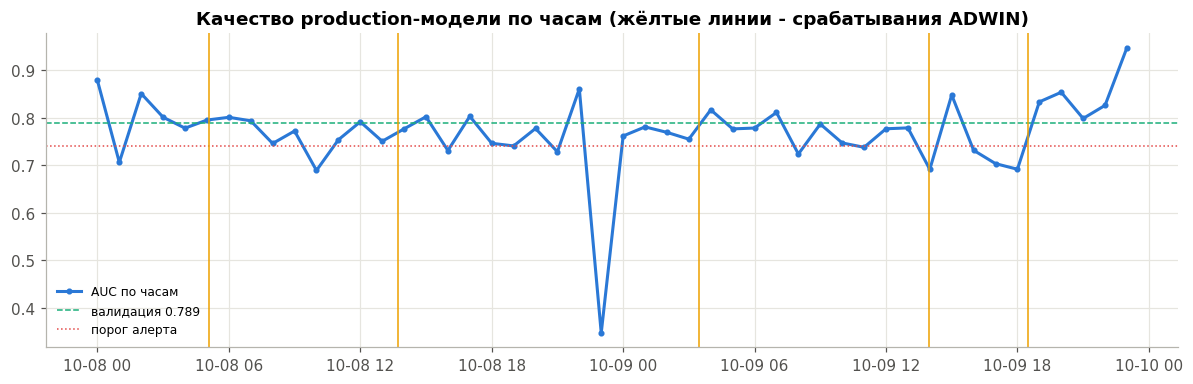

Срабатываний ADWIN: 5 [Timestamp('2019-10-08 05:06:15'), Timestamp('2019-10-08 13:44:29'), Timestamp('2019-10-09 03:26:39'), Timestamp('2019-10-09 13:56:58'), Timestamp('2019-10-09 18:28:01')]


In [63]:
from river import drift as rdrift
mon = pd.concat([fs_test, fs_next], ignore_index=True).sort_values('event_timestamp').reset_index(drop=True)
mon['score'] = prod_loaded.predict_proba(mon[FEATS])[:, 1]
mon['hour_ts'] = mon.event_timestamp.dt.floor('h')
val_scores = prod_loaded.predict_proba(fs_val[FEATS])[:, 1]
baseline_auc = roc_auc_score(fs_val['label'], val_scores)
hourly_auc = mon.groupby('hour_ts').apply(lambda d: roc_auc_score(d.label, d.score) if d.label.nunique() == 2 and len(d) > 200 else np.nan)
pred_psi = {d: DD.psi(val_scores, g.score) for d, g in mon.groupby(mon.event_timestamp.dt.date)}
det = rdrift.ADWIN(delta=0.002)
drift_points = []
for t, e in zip(mon.event_timestamp, np.abs(mon.label - mon.score)):
    det.update(e)
    if det.drift_detected:
        drift_points.append(t)

def monitor_model_performance(day_df):
    current = roc_auc_score(day_df.label, day_df.score)
    drop = baseline_auc - current
    with mlflow.start_run(run_name='model-monitoring', nested=False):
        mlflow.log_metric('accuracy_drift', drop)
    if drop > DD.AUC_DROP_ALERT:
        DD.send_alert('work/logs', 'warning', 'auc_drop', f'AUC упал на {drop:.3f}')
    return current, drop

mm = pd.DataFrame([{'день': d, 'AUC': monitor_model_performance(g)[0], 'падение AUC': baseline_auc - roc_auc_score(g.label, g.score),
                    'PSI оценок': pred_psi[d], 'средняя оценка': g.score.mean(), 'доля положительных': g.label.mean()}
                   for d, g in mon.groupby(mon.event_timestamp.dt.date)])
display(mm.round(4))
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(hourly_auc.index, hourly_auc.values, color=COLORS[0], marker='.', label='AUC по часам')
ax.axhline(baseline_auc, color=COLORS[1], ls='--', lw=1, label=f'валидация {baseline_auc:.3f}')
ax.axhline(baseline_auc - DD.AUC_DROP_ALERT, color=COLORS[5], ls=':', lw=1, label='порог алерта')
for t in drift_points:
    ax.axvline(t, color=COLORS[4], lw=1)
ax.set_title('Качество production-модели по часам (жёлтые линии - срабатывания ADWIN)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Срабатываний ADWIN:', len(drift_points), drift_points[:5])
for t in drift_points:
    DD.send_alert('work/logs', 'info', 'concept_drift', f'ADWIN: изменилась средняя ошибка модели в {t}')

### 3) Настройте алертинг:

| Что | Порог | Почему | Действие |
|---|---|---|---|
| Data drift (PSI фичи) | > 0,1 предупреждение, > 0,2 дрейф | стандартные границы PSI из лекции | отметка в отчёте |
| Доля сдвинутых фич | > 20% алерт, > 30% retrain | один сдвинутый признак модель переносит, массовый сдвиг - нет | алерт / переобучение |
| Пропуски в фиче | > 5% сверх эталона | лекция, таблица мониторинга | алерт, проверка пайплайна фич |
| Падение AUC | > 0,05 алерт, > 0,10 retrain | 0,05 - больше суточного разброса AUC (таблица выше) | алерт / переобучение |
| Сдвиг отдельной фичи | PSI > 0,2 | даже одна сдвинутая фича означает сбой в пайплайне фич или в источнике | алерт `feature_drift`, проверка источника, не retrain |
| ADWIN по ошибке | срабатывание | статистически значимое изменение средней ошибки | информационный алерт, проверка concept drift |

Алерт пишется в `work/logs/alerts.jsonl`, при заданных переменных окружения уходит в Slack (`SLACK_WEBHOOK_URL`) и на почту (`ALERT_EMAIL`, `SMTP_HOST`).

In [64]:
alerts = pd.read_json('work/logs/alerts.jsonl', lines=True) if os.path.exists('work/logs/alerts.jsonl') else pd.DataFrame()
display(alerts.groupby(['level', 'kind']).size().rename('алертов').to_frame() if len(alerts) else 'алертов нет')
display(alerts.drop_duplicates('kind')[['level', 'kind', 'message']] if len(alerts) else '')

,,алертов
level,kind,
info,concept_drift,5
warning,feature_drift,1


,level,kind,message
0,warning,feature_drift,"2019-10-09 (цены x1,5): price_ratio PSI=9.81 > 0.2"
1,info,concept_drift,ADWIN: изменилась средняя ошибка модели в 2019-10-08 05:06:15


### 4) Реализуйте автоматический retrain:

In [65]:
def get_drift_score(day):
    return DD.drift_score(drift_tables[day])
def get_accuracy_drift(day):
    return float(mm.set_index('день').loc[pd.Timestamp(day).date(), 'падение AUC'])

retrain_log = []
for day, days_since in ((TEST_DAY, 2), (NEXT_DAY, 3)):
    need, reasons = DD.check_retrain_needed(get_drift_score(day), get_accuracy_drift(day), days_since)
    retrain_log.append({'день': day, 'drift_score': get_drift_score(day), 'падение AUC': get_accuracy_drift(day),
                        'retrain': need, 'причины': '; '.join(reasons) or '-'})
need, reasons = DD.check_retrain_needed(get_drift_score(NEXT_DAY), get_accuracy_drift(NEXT_DAY), 7)
retrain_log.append({'день': f'{NEXT_DAY}, 7 дней с обучения', 'drift_score': get_drift_score(NEXT_DAY),
                    'падение AUC': get_accuracy_drift(NEXT_DAY), 'retrain': need, 'причины': '; '.join(reasons) or '-'})
need, reasons = DD.check_retrain_needed(DD.drift_score(drift_tables[f'{NEXT_DAY} (цены x1,5)']), 0.0, 3)
retrain_log.append({'день': f'{NEXT_DAY} (цены x1,5)', 'drift_score': DD.drift_score(drift_tables[f'{NEXT_DAY} (цены x1,5)']),
                    'падение AUC': np.nan, 'retrain': need, 'причины': '; '.join(reasons) or '-'})
display(pd.DataFrame(retrain_log).round(4))

,день,drift_score,падение AUC,retrain,причины
0,2019-10-08,0.0000,0.010,False,-
1,2019-10-09,0.0000,0.014,False,-
2,"2019-10-09, 7 дней с обучения",0.0000,0.014,True,плановое переобучение: 7 дн. с последнего
3,"2019-10-09 (цены x1,5)",0.0556,NaN,False,-


**Требования к отчету:**

- **Код мониторинга данных:** `monitoring/drift_detection.py`.
- **Примеры отчетов о data drift:** таблицы пункта 1, HTML-отчёты Evidently `work/drift_*.html`, метрики `drift_score` в MLflow. На 8 и 9 октября дрейфа нет: `drift_score` 0,0 (0 из 18 фич с PSI > 0,2), максимальный PSI 0,079 (`u_active_days_7d`) и 0,048. Искусственный сдвиг цен ×1,5 ловится: у `price_ratio` PSI 9,81 и 98% значений вне диапазона эталона, остальные 17 фич спокойны. Evidently с настройками по умолчанию помечает сдвинутыми 56%, 39% и 44% колонок, то есть почти одинаково на штатных днях и на искусственном сдвиге (39% против 44%), а KS-тест на десятках тысяч строк даёт p-value около 0 почти везде. Поэтому решения принимаются по PSI, а Evidently служит для просмотра распределений. Автоматический retrain в пункте 4 сработал только по плановому сроку (7 дней с обучения): сдвиг одной фичи (5,6% < 30%) даёт алерт `feature_drift`, но не переобучение, как и задумано.
- **Стратегия алертинга:** таблица пункта 3.
- **Логика автоматического retrain:** `check_retrain_needed`: переобучение при доле сдвинутых фич > 30%, падении AUC > 0,10 или раз в 7 дней; пример решений в пункте 4.

## Часть 6: Сравнение стратегий обучения

### 1) Реализуйте пакетное обучение:

Пакетная стратегия: модель переобучается раз в сутки на всех доступных днях из Feature Store, логируется в MLflow, регистрируется и выкатывается через canary. Модель на 8 октября обучена на 5-7 октября, модель на 9 октября - на 5-8 октября.

In [66]:
def batch_training(train_days, label):
    data = pd.concat([fs_sets[d] for d in train_days], ignore_index=True)
    m = BT.make_models(SEED, N_JOBS)[BEST]
    t0 = time.perf_counter()
    mlflow.set_experiment('batch-training')
    with mlflow.start_run(run_name=label) as r:
        m.fit(data[FEATS], data['label'])
        fit_s = time.perf_counter() - t0
        mlflow.log_params({'train_days': ','.join(train_days), 'n_train': len(data)})
        mlflow.log_metric('fit_seconds', fit_s)
        mlflow.sklearn.log_model(m, name='model', serialization_format='cloudpickle')
    return m, fit_s, r.info.run_id

batch_d8, fit_d8, run_d8 = batch_training(TRAIN_DAYS + [VAL_DAY], 'daily-2019-10-08')
batch_d9, fit_d9, run_d9 = batch_training(TRAIN_DAYS + [VAL_DAY, TEST_DAY], 'daily-2019-10-09')
ver_d9 = BT.register(run_d9, stage='Staging', description='ежедневное переобучение на 9 октября')
API.configure(canary={'model': batch_d9, 'features': FEATS, 'version': f'v{ver_d9}'}, canary_percent=5,
              canary_stats={'requests': 0, 'errors': 0, 'latency_ms': []}, rollback_reason=None)
m_d9 = measure_metrics([dict(user_id=int(r.user_id), product_id=int(r.product_id), price=float(r.price), hour=int(r.hour))
                        for r in fs_next.sample(500, random_state=SEED).itertuples()], 4)
print(f"Canary v{ver_d9}: ошибок {m_d9['error_rate']:.3f}, p95 {m_d9['p95_ms']:.1f} мс, откат: {http.get('/health').json()['rollback_reason']}")
API.configure(canary=None, canary_percent=0)
print(f'Время обучения: {fit_d8:.1f} с и {fit_d9:.1f} с')

🏃 View run daily-2019-10-08 at: http://127.0.0.1:5055/#/experiments/2/runs/d5d38bc1d4db4d4f82fe12923b468c82
🧪 View experiment at: http://127.0.0.1:5055/#/experiments/2
🏃 View run daily-2019-10-09 at: http://127.0.0.1:5055/#/experiments/2/runs/997f07ae3a154af39aa74b70bd170e00
🧪 View experiment at: http://127.0.0.1:5055/#/experiments/2


Registered model 'RecoRanker' already exists. Creating a new version of this model...
Created version '5' of model 'RecoRanker'.


Canary v5: ошибок 0.000, p95 89.4 мс, откат: None
Время обучения: 8.3 с и 10.0 с


### 2) Реализуйте онлайн-обучение:

Онлайн-стратегия: логистическая регрессия River (как в задании) стартует с модели, обученной одним проходом на 5-7 октября, затем учится на каждом событии потока 8-9 октября. Фичи для каждого события берутся из Feature Store (снимок на начало дня, тот же, что видит сервис). Качество меряется прогрессивно: сначала предсказание, затем обучение на этой же строке, так что оценка всегда идёт на ещё не виденных данных. Каждые 5000 событий модель «деплоится» - сохраняется в MLflow как новая версия артефакта.

In [67]:
import pickle
stream = pd.concat([fs_test, fs_next], ignore_index=True).sort_values('event_timestamp').reset_index(drop=True)
online = OT.warm_start(OT.make_online(), pd.concat([fs_train, fs_val]), FEATS)
mlflow.set_experiment('online-training')
deploys = []
def on_deploy(model, n):
    deploys.append(n)
    with open('work/online_model.pkl', 'wb') as fh:
        pickle.dump(model, fh)
    mlflow.log_artifact('work/online_model.pkl', artifact_path=f'deploy_{n}')
with mlflow.start_run(run_name='river-stream-8-9oct'):
    t0 = time.perf_counter()
    p_on, upd_s, on_drifts = OT.run_stream(online, stream, FEATS, deploy_every=5000, on_deploy=on_deploy)
    stream_s = time.perf_counter() - t0
    mlflow.log_metrics({'auc_progressive': roc_auc_score(stream.label, p_on), 'update_seconds': upd_s, 'deploys': len(deploys)})
stream['p_online'] = p_on
print(f'Событий в потоке: {len(stream)}, обновлений модели: {len(stream)}, время обновлений {upd_s:.1f} с, '
      f'деплоев: {len(deploys)}, срабатываний ADWIN: {len(on_drifts)}')

🏃 View run river-stream-8-9oct at: http://127.0.0.1:5055/#/experiments/3/runs/92d70926c3cc4c38ab0d16524f969bac
🧪 View experiment at: http://127.0.0.1:5055/#/experiments/3
Событий в потоке: 89854, обновлений модели: 89854, время обновлений 4.5 с, деплоев: 17, срабатываний ADWIN: 6


### 3) Сравните стратегии:

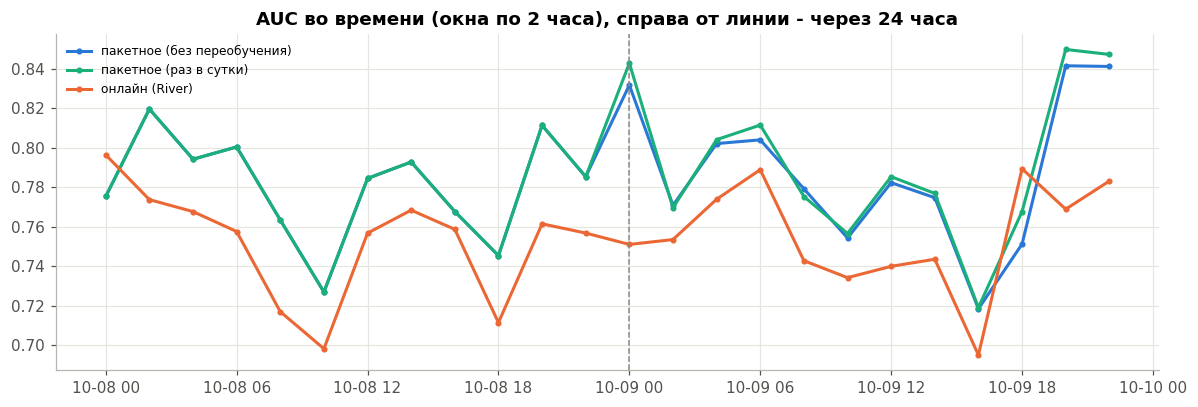

,стратегия,AUC 8 окт,AUC через 24 ч (9 окт),"latency p50, мс","latency p99, мс","CPU на обновление за сутки, с","стоимость обновлений в месяц, ₽",сложность инфраструктуры
0,пакетное раз в сутки,0.7857,0.7871,1.2605,2.2282,9.9809,0.1031,низкая: планировщик + MLflow + Feast batch
1,онлайн (River),0.7568,0.7601,0.0076,0.0150,2.2528,0.0233,"высокая: поток (Kafka), состояние модели, постоянный процесс, частый деплой"


🏃 View run batch-vs-online-24h at: http://127.0.0.1:5055/#/experiments/4/runs/507b7cd73e6c4f429a3bf9ec103dd485
🧪 View experiment at: http://127.0.0.1:5055/#/experiments/4


In [68]:
stream['p_batch_static'] = batch_d8.predict_proba(stream[FEATS])[:, 1]                     # без переобучения
is_d9 = stream.event_timestamp >= pd.Timestamp(NEXT_DAY)
stream['p_batch_daily'] = stream['p_batch_static']
stream.loc[is_d9, 'p_batch_daily'] = batch_d9.predict_proba(stream.loc[is_d9, FEATS])[:, 1]  # переобучение раз в сутки
stream['h'] = stream.event_timestamp.dt.floor('2h')

def auc_by(col):
    return stream.groupby('h').apply(lambda d: roc_auc_score(d.label, d[col]) if d.label.nunique() == 2 else np.nan)

curves = pd.DataFrame({'пакетное (без переобучения)': auc_by('p_batch_static'), 'пакетное (раз в сутки)': auc_by('p_batch_daily'),
                       'онлайн (River)': auc_by('p_online')})
fig, ax = plt.subplots(figsize=(11, 3.8))
for (c, s), col in zip(curves.items(), COLORS):
    ax.plot(s.index, s.values, marker='.', color=col, label=c)
ax.axvline(pd.Timestamp(NEXT_DAY), color='#8a8984', ls='--', lw=1)
ax.set_title('AUC во времени (окна по 2 часа), справа от линии - через 24 часа'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

def lat_online(n=300):
    recs = OT.to_records(stream.sample(n, random_state=SEED), FEATS)
    t = []
    for x in recs:
        t0 = time.perf_counter(); online.predict_proba_one(x); t.append((time.perf_counter() - t0) * 1000)
    return np.percentile(t, 50), np.percentile(t, 99)
lb = BT.latency_ms(batch_d9, stream[FEATS])
lo = lat_online()
cpu_cost = lambda s: s / 3600 * PRICE['vm_vcpu_hour']
cmp_s = pd.DataFrame([
    {'стратегия': 'пакетное раз в сутки', 'AUC 8 окт': roc_auc_score(stream.label[~is_d9], stream.p_batch_daily[~is_d9]),
     'AUC через 24 ч (9 окт)': roc_auc_score(stream.label[is_d9], stream.p_batch_daily[is_d9]),
     'latency p50, мс': lb['p50_ms'], 'latency p99, мс': lb['p99_ms'], 'CPU на обновление за сутки, с': fit_d9,
     'стоимость обновлений в месяц, ₽': cpu_cost(fit_d9) * 30,
     'сложность инфраструктуры': 'низкая: планировщик + MLflow + Feast batch'},
    {'стратегия': 'онлайн (River)', 'AUC 8 окт': roc_auc_score(stream.label[~is_d9], stream.p_online[~is_d9]),
     'AUC через 24 ч (9 окт)': roc_auc_score(stream.label[is_d9], stream.p_online[is_d9]),
     'latency p50, мс': lo[0], 'latency p99, мс': lo[1], 'CPU на обновление за сутки, с': upd_s / 2,
     'стоимость обновлений в месяц, ₽': cpu_cost(upd_s / 2) * 30,
     'сложность инфраструктуры': 'высокая: поток (Kafka), состояние модели, постоянный процесс, частый деплой'}])
display(cmp_s.round(4))
ONLINE_BATCH_DIFFERENCE = float(cmp_s.loc[0, 'AUC через 24 ч (9 окт)'] - cmp_s.loc[1, 'AUC через 24 ч (9 окт)'])
mlflow.set_experiment('reco-ranker-registry')
with mlflow.start_run(run_name='batch-vs-online-24h'):
    mlflow.log_metrics({'batch_auc_24h': cmp_s.loc[0, 'AUC через 24 ч (9 окт)'], 'online_auc_24h': cmp_s.loc[1, 'AUC через 24 ч (9 окт)'],
                        'difference': ONLINE_BATCH_DIFFERENCE})

### 4) Определите оптимальную стратегию:

**Для каких данных лучше пакетное обучение?** Когда зависимости меняются медленно (сутки и дольше), фичи считаются окнами (у нас 7 дней, снимок раз в сутки) и важны воспроизводимость и проверка перед выкладкой: модель обучается на зафиксированном наборе из Feature Store, проходит валидацию и canary. В эксперименте пакетная модель точнее: AUC через 24 часа 0,7871 против 0,7601 у онлайн-модели (разница 0,027). Ежедневное переобучение улучшает кривую лишь слегка, потому что за сутки распределение почти не сдвинулось (`drift_score` 0).

**Для каких данных лучше онлайн-обучение?** Для быстро меняющихся данных, где метка приходит сразу, а свежесть нужна за минуты: всплески спроса, акции, новые товары, ленты новостей. В нашем эксперименте онлайн-модель (логистическая регрессия River) слабее (AUC 0,7601 против 0,7871), зато обновление и предсказание дешевле: 2,3 с CPU на сутки против 10,0 с, p50 0,008 мс против 1,3 мс. По деньгам разница ничтожна (0,02 ₽ и 0,10 ₽ в месяц), а инфраструктура у онлайна сложнее: поток событий, состояние модели, постоянный процесс, частый деплой.

**Какой гибридный подход оптимален?** Пакетная LightGBM раз в сутки как основа (качество, воспроизводимость, canary и откат), лёгкий онлайн-слой поверх неё для внутридневной поправки и мониторинг дрейфа, который запускает внеплановое переобучение при превышении порогов. На наших двух днях дрейфа нет, поэтому онлайн-слой пока не окупается; он имеет смысл при заметном внутридневном сдвиге.

**Требования к отчету:**

- **Код реализации обеих стратегий:** `training/batch_training.py`, `training/online_training.py`, ячейки пунктов 1-2.
- **Таблица сравнения метрик:** пункт 3.
- **График изменения accuracy во времени:** пункт 3 (AUC по двухчасовым окнам).
- **Рекомендации по выбору стратегии:** пункт 4.

## Часть 7: Реализация уникального требования

### 1) Реализуйте ваше уникальное требование (см. таблицу выше):

**Обработка холодных стартеров.** Холодный пользователь - без событий за 7 дней до запроса, Feature Store возвращает для него пустые фичи (Часть 2, пункт 5). В тестовом дне на них приходится около половины пар (таблица EDA, `cold_share`), поэтому от обработки холодного старта зависит качество для значительной части трафика.

In [69]:
%%writefile training/cold_start.py
"""Обработка холодного старта (вариант 5).

Холодный пользователь - без единого события за 7 дней до момента запроса: в Feature Store для него нет
снимка, и все пользовательские фичи пусты. Наивный вариант (ошибка из лекции) - заполнить их нулями.
Здесь вместо этого:
1) флаг is_cold, чтобы модель отличала «нет истории» от «смотрел, но не покупал»;
2) априорные значения: медианы фич у пользователей с минимальной историей (1 активный день) вместо нулей;
3) feature dropout при обучении: у части тёплых пользователей фичи скрываются, и модель учится на «холодных»
   примерах из тех же сессий;
4) для рекомендаций без истории - популярное в категории текущего товара, а не глобальный топ.
"""
import numpy as np
import pandas as pd

from .data import USER_FEATURES


def is_cold(df):
    return df['u_views_7d'].isna() | (df['u_views_7d'] <= 0)


def user_priors(train):
    """Априорные значения фич пользователя: медианы у тех, кто был активен ровно 1 день из 7."""
    newbies = train[train['u_active_days_7d'] == 1]
    return {c: float(newbies[c].median()) for c in USER_FEATURES}


def baseline_fill(df):
    """Наивная обработка: пустые пользовательские фичи заполняются нулями."""
    out = df.copy()
    out[USER_FEATURES] = out[USER_FEATURES].fillna(0.0)
    return out


def cold_fill(df, priors):
    """Обработка холодного старта: флаг и априорные значения вместо нулей."""
    out = df.copy()
    out['is_cold'] = is_cold(out).astype(float)
    for c in USER_FEATURES:
        out[c] = out[c].where(~out['is_cold'].astype(bool), priors[c])
    return out


def feature_dropout(train, priors, frac=0.15, seed=42):
    """Копия части тёплых строк, где пользовательские фичи скрыты (как у холодного пользователя)."""
    rng = np.random.default_rng(seed)
    warm = train[~is_cold(train)]
    idx = rng.choice(len(warm), size=int(len(warm) * frac), replace=False)
    aug = warm.iloc[idx].copy()
    aug[USER_FEATURES] = np.nan
    return pd.concat([train, aug], ignore_index=True)


def category_fallback(product_daily, as_of, k=10):
    """Популярные товары по категориям за 7 дней до as_of: список рекомендаций для пользователя без истории."""
    t = pd.Timestamp(as_of)
    w = product_daily[(pd.to_datetime(product_daily['day']) >= t - pd.Timedelta(days=7)) &
                      (pd.to_datetime(product_daily['day']) < t)]
    agg = (w.groupby(['category_id', 'product_id'], as_index=False)[['purchases', 'carts', 'views']].sum()
             .sort_values(['category_id', 'purchases', 'carts', 'views'], ascending=[True, False, False, False]))
    by_cat = agg.groupby('category_id').head(k).groupby('category_id')['product_id'].apply(list).to_dict()
    glob = (agg.sort_values(['purchases', 'carts', 'views'], ascending=False).head(k)['product_id'].tolist())
    return by_cat, glob

Overwriting training/cold_start.py


Сравниваются три варианта ранжировщика на одной обучающей выборке:
- **baseline (ошибка из лекции):** пустые пользовательские фичи заполнены нулями, модель не отличает «нет истории» от «смотрел и ничего не купил»;
- **NaN как есть:** LightGBM сам выбирает направление для пропусков (стандартное поведение без специальной обработки);
- **обработка холодного старта:** флаг `is_cold`, априорные значения вместо нулей и feature dropout (15% тёплых строк обучения с искусственно скрытой историей).

Для рекомендаций без истории сравниваются два запасных списка: глобальный топ и популярное в категории просматриваемого товара. Качество меряется HitRate@10: доля холодных пользователей, которые в тот же день после первого просмотра взаимодействовали хотя бы с одним товаром списка.

In [70]:
pri = CS.user_priors(fs_train)
variants = {
    'baseline: нули': (CS.baseline_fill(fs_train), lambda d: CS.baseline_fill(d), FEATS),
    'NaN как есть': (fs_train, lambda d: d, FEATS),
    'обработка холодного старта': (CS.cold_fill(CS.feature_dropout(fs_train, pri, 0.15, SEED), pri),
                                   lambda d: CS.cold_fill(d, pri), FEATS + ['is_cold']),
}
cold_test = CS.is_cold(fs_test)
cs_rows, cs_models = [], {}
for name, (tr_df, prep, feats) in variants.items():
    m = BT.make_models(SEED, N_JOBS)[BEST]
    t0 = time.perf_counter(); m.fit(tr_df[feats], tr_df['label']); fit_s = time.perf_counter() - t0
    te = prep(fs_test)
    p = m.predict_proba(te[feats])[:, 1]
    lat = BT.latency_ms(m, te[feats])
    cs_models[name] = (m, prep, feats)
    cs_rows.append({'вариант': name, 'AUC все': roc_auc_score(te.label, p),
                    'AUC холодные': roc_auc_score(te.label[cold_test], p[cold_test]),
                    'AUC тёплые': roc_auc_score(te.label[~cold_test], p[~cold_test]),
                    'обучение, с': fit_s, 'строк обучения': len(tr_df), 'latency p50, мс': lat['p50_ms']})
cs_res = pd.DataFrame(cs_rows)
display(cs_res.round(4))
print(f'Холодных пар в тесте: {cold_test.mean():.1%}')

,вариант,AUC все,AUC холодные,AUC тёплые,"обучение, с",строк обучения,"latency p50, мс"
0,baseline: нули,0.7808,0.7424,0.8082,5.4827,84322,1.9630
1,NaN как есть,0.7795,0.7429,0.8057,4.6984,84322,1.1500
2,обработка холодного старта,0.7795,0.7427,0.8056,5.2101,90154,2.1083


Холодных пар в тесте: 50.4%


### 2) Измерьте эффект от реализации:

In [71]:
first_view = (fs_test[cold_test].sort_values('event_timestamp').groupby('user_id').head(1)[['user_id', 'product_id', 'event_timestamp']])
later = ev[(ev.event_time.dt.date == pd.Timestamp(TEST_DAY).date())][['user_id', 'product_id', 'event_time']]
hits = {'глобальный топ': [], 'популярное в категории товара': []}
for r in first_view.itertuples():
    after = set(later[(later.user_id == r.user_id) & (later.event_time > r.event_timestamp)].product_id)
    cat_list = by_cat.get(last_cat.get(r.product_id), [])[:10] or glob_top[:10]
    hits['глобальный топ'].append(bool(after & set(glob_top[:10])))
    hits['популярное в категории товара'].append(bool(after & set(cat_list)))
hr = pd.DataFrame({k: [np.mean(v)] for k, v in hits.items()}, index=['HitRate@10 холодных пользователей']).T
display(hr.round(4))

base, best = cs_res.set_index('вариант').loc['baseline: нули'], cs_res.set_index('вариант').loc['обработка холодного старта']
effect = pd.DataFrame([
    {'метрика': 'AUC на холодных', 'baseline': base['AUC холодные'], 'с обработкой': best['AUC холодные']},
    {'метрика': 'AUC на всех', 'baseline': base['AUC все'], 'с обработкой': best['AUC все']},
    {'метрика': 'latency p50 модели, мс', 'baseline': base['latency p50, мс'], 'с обработкой': best['latency p50, мс']},
    {'метрика': 'время обучения, с', 'baseline': base['обучение, с'], 'с обработкой': best['обучение, с']},
    {'метрика': 'стоимость обучения в месяц (ежедневно), ₽', 'baseline': base['обучение, с'] / 3600 * PRICE['vm_vcpu_hour'] * 30,
     'с обработкой': best['обучение, с'] / 3600 * PRICE['vm_vcpu_hour'] * 30},
    {'метрика': 'HitRate@10 запасного списка', 'baseline': hr.iloc[0, 0], 'с обработкой': hr.iloc[1, 0]}])
effect['разница'] = effect['с обработкой'] - effect['baseline']
display(effect.round(4))
UNIQUE_REQUIREMENT_IMPACT = float(hr.iloc[1, 0] - hr.iloc[0, 0])     # прирост HitRate@10 холодных пользователей

# эффект в сервисе: production-версия против версии с обработкой холодного старта, запросы холодных пользователей
cm, cprep, cfeats = cs_models['обработка холодного старта']
cold_payloads = [dict(user_id=int(r.user_id), product_id=int(r.product_id), price=float(r.price), hour=int(r.hour))
                 for r in fs_test[cold_test].sample(500, random_state=SEED).itertuples()]
svc = []
for label, entry in (('production (NaN, без обработки)', {'model': prod_loaded, 'features': FEATS, 'version': f'v{ver1}'}),
                     ('с обработкой холодного старта', {'model': cm, 'features': cfeats, 'version': 'v-cold', 'prep': cprep})):
    API.configure(primary=entry)
    mt = measure_metrics(cold_payloads, 1)
    svc.append({'версия в сервисе': label, 'p50, мс': mt['p50_ms'], 'p99, мс': mt['p99_ms'], 'ошибок': mt['error_rate']})
API.configure(primary={'model': prod_loaded, 'features': FEATS, 'version': f'v{ver1}'})
display(pd.DataFrame(svc).round(3))

,HitRate@10 холодных пользователей
глобальный топ,0.0806
популярное в категории товара,0.2733


,метрика,baseline,с обработкой,разница
0,AUC на холодных,0.7424,0.7427,0.0003
1,AUC на всех,0.7808,0.7795,-0.0013
2,"latency p50 модели, мс",1.9630,2.1083,0.1453
3,"время обучения, с",5.4827,5.2101,-0.2726
4,"стоимость обучения в месяц (ежедневно), ₽",0.0567,0.0538,-0.0028
5,HitRate@10 запасного списка,0.0806,0.2733,0.1928


,версия в сервисе,"p50, мс","p99, мс",ошибок
0,"production (NaN, без обработки)",11.995,20.195,0.0
1,с обработкой холодного старта,17.292,32.581,0.0


**Как это повлияло на метрики качества?** AUC ранжировщика почти не изменился: на холодных парах 0,7424 → 0,7427 (+0,0003), на всех 0,7808 → 0,7795 (−0,0013), на тёплых 0,8082 → 0,8056. LightGBM и так сам обрабатывает пропуски (вариант «NaN как есть»: 0,7429 на холодных). Заметный эффект даёт запасной список для пользователей без истории: HitRate@10 вырос с 0,0806 (глобальный топ) до 0,2733 (популярное в категории текущего товара), то есть в 3,4 раза (+0,193). Холодные пары составляют 50,4% тестового дня, так что это значимая доля трафика.

**Как это повлияло на latency?** Предсказание модели: p50 1,96 → 2,11 мс. В сервисе на запросах холодных пользователей p50 вырос с 12,0 до 17,3 мс, p99 с 20,2 до 32,6 мс (предобработка, флаг и априорные значения). Это укладывается в 100 мс.

**Как это повлияло на cost metrics?** Строк обучения стало на 7% больше (90 154 против 84 322), время обучения 5,48 → 5,21 с, стоимость ежедневного обучения 0,057 → 0,054 ₽ в месяц: разница в пределах шума. Запасной список строится из дневной агрегации и не требует обучения.

### 3) Сравните с baseline:

Baseline (без реализации уникального требования) и вариант с реализацией сравнены в таблицах пунктов 1 и 2 на одном тестовом дне и одной модели. По AUC разница в пределах 0,002 (на холодных +0,0003, на всех −0,0013): флаг, априорные значения и feature dropout качества ранжирования не добавили. По HitRate@10 запасного списка прирост +0,193 (0,0806 → 0,2733).

**Требования к отчету:**

- **Код реализации уникального требования:** `training/cold_start.py`, `api/main.py` (холодный пользователь получает априорные значения и флаг, запасной список по категории текущего товара).
- **Измерение эффекта с цифрами:** пункт 2.
- **Сравнение с baseline:** пункты 1-2.
- **Вывод о применимости в production:** запасной список «популярное в категории текущего товара» для пользователей без истории применять: он даёт основной эффект, не требует обучения и укладывается в latency. Обработку холодного старта внутри модели (флаг, априорные значения, dropout) в текущем виде внедрять не стоит: качество не выросло, а задержка в сервисе выросла примерно на 5 мс; достаточно оставить NaN, которые LightGBM обрабатывает сам. Ограничение: HitRate измерен офлайн на одном дне, рост CTR на 10% без A/B-теста не проверяется.

## Часть 8: Прогноз сенсора и автоотключение

### 1) **Данные.** Возьмите датасет NAB `ambient_temperature_system_failure.csv` - почасовой ряд температуры системы:

Ряд приводится к регулярной почасовой сетке. В ней 621 пропущенный час, в том числе 6 дней подряд внутри второй аварии. Пропуски интерполируются только для построения признаков, а метрики считаются по наблюдённым точкам.

Разбиение по времени:
- обучение моделей: 4 июля - 30 ноября 2013 (только нормальная работа);
- выбор порогов тревоги: 1 декабря 2013 - 28 февраля 2014, внутри первая авария (15-30.12.2013);
- финальная проверка: 1 марта - 28 мая 2014, внутри вторая авария (29.03-20.04.2014). Она не участвует ни в обучении, ни в выборе порогов.

In [72]:
%%writefile forecasting/sensor.py
"""Часть 8: прогноз температуры сенсора (LightGBM с лагами), квантили, рекурсивная и прямая стратегии,
решающий слой автоотключения из четырёх условий и метрики раннего предупреждения."""
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor

URL = ('https://raw.githubusercontent.com/numenta/NAB/master/data/realKnownCause/'
       'ambient_temperature_system_failure.csv')
FAILURES = [(pd.Timestamp('2013-12-15'), pd.Timestamp('2013-12-30 23:00')),
            (pd.Timestamp('2014-03-29'), pd.Timestamp('2014-04-20 23:00'))]
LAGS = [1, 2, 3, 6, 12, 24, 48, 168]
QUANTILES = [0.01, 0.05, 0.1, 0.5, 0.9, 0.95, 0.99]


def load(src=URL):
    df = pd.read_csv(src, parse_dates=['timestamp']).set_index('timestamp').asfreq('h')
    df['observed'] = df['value'].notna()
    df['y'] = df['value'].interpolate('time')     # для признаков; метрики считаются только по наблюдениям
    return df


def features_from_array(a, t_index):
    """Признаки момента t по истории a[..t] (a[-1] = значение в момент t)."""
    n = len(a)
    row = {f'lag_{k - 1}': a[n - k] for k in LAGS}
    row.update({'lag_0': a[-1], 'mean_24': a[-24:].mean(), 'std_24': a[-24:].std(), 'mean_168': a[-168:].mean(),
                'diff_1': a[-1] - a[-2], 'diff_24': a[-1] - a[-25],
                'hour': t_index.hour, 'dow': t_index.dayofweek})
    return row


def make_features(y):
    """Таблица признаков для всех моментов: только прошлые и текущее значения, без заглядывания вперёд."""
    X = pd.DataFrame(index=y.index)
    X['lag_0'] = y
    for k in LAGS:
        X[f'lag_{k - 1}'] = y.shift(k - 1)
    X['mean_24'] = y.rolling(24).mean()
    X['std_24'] = y.rolling(24).std(ddof=0)
    X['mean_168'] = y.rolling(168).mean()
    X['diff_1'] = y.diff(1)
    X['diff_24'] = y.diff(24)
    X['hour'] = y.index.hour
    X['dow'] = y.index.dayofweek
    return X


FEATS = None


def _lgbm(objective='regression', alpha=None, seed=42):
    kw = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=30, subsample=0.8,
              subsample_freq=1, colsample_bytree=0.8, random_state=seed, verbose=-1, n_jobs=2)
    return LGBMRegressor(objective=objective, alpha=alpha, **kw) if alpha else LGBMRegressor(objective=objective, **kw)


def fit_direct(df, train_end, H, quantiles=QUANTILES, seed=42):
    """Прямая стратегия: отдельные модели на каждый шаг h (точка L2 и квантили)."""
    global FEATS
    X = make_features(df['y'])
    FEATS = list(X.columns)
    models = {}
    for h in range(1, H + 1):
        # цель - приращение y(t+h) - y(t): деревья не выходят за диапазон обучающих целей, а уровень
        # прибавляется к прогнозу приращения, поэтому прогноз может уйти выше максимума обучения
        target = df['y'].shift(-h) - df['y']
        ok = df['observed'].shift(-h, fill_value=False) & X.notna().all(axis=1) & (X.index <= train_end - pd.Timedelta(hours=h))
        Xt, yt = X[ok], target[ok]
        models[(h, 'point')] = _lgbm(seed=seed).fit(Xt, yt)
        for q in quantiles:
            models[(h, q)] = _lgbm('quantile', q, seed).fit(Xt, yt)
    return models, X


def predict_direct(models, X, origins, H, quantiles=QUANTILES):
    """Прогнозы прямой стратегии из каждого момента origins на шаги 1..H: DataFrame (origin, h, point, q...)."""
    Xo = X.loc[origins]
    out = []
    level = Xo['lag_0'].to_numpy()
    for h in range(1, H + 1):
        d = pd.DataFrame({'origin': origins, 'h': h, 'point': level + models[(h, 'point')].predict(Xo)})
        for q in quantiles:
            d[f'q{q}'] = level + models[(h, q)].predict(Xo)
        out.append(d)
    res = pd.concat(out, ignore_index=True)
    qs = [f'q{q}' for q in quantiles]
    res[qs] = np.sort(res[qs].to_numpy(), axis=1)   # квантили не должны пересекаться
    return res


def predict_recursive(models, y, origins, H, q=0.9):
    """Рекурсивная стратегия: одношаговые модели (h=1), прогноз подставляется как факт для следующего шага.
    Квантиль на шаге h - одношаговый квантиль от уже спрогнозированной траектории (неопределённость прошлых
    шагов в нём не накапливается)."""
    m_point, m_q = models[(1, 'point')], models[(1, q)]
    vals = y.to_numpy()
    pos = {t: i for i, t in enumerate(y.index)}
    rows = []
    for o in origins:
        i = pos[o]
        a = list(vals[i - 200:i + 1])
        t = o
        for h in range(1, H + 1):
            xr = pd.DataFrame([features_from_array(np.asarray(a), t)])[FEATS]
            p, pq = a[-1] + m_point.predict(xr)[0], a[-1] + m_q.predict(xr)[0]
            rows.append({'origin': o, 'h': h, 'point': p, f'q{q}': pq})
            a.append(p)
            t = t + pd.Timedelta(hours=1)
    return pd.DataFrame(rows)


def pinball(y, qpred, q):
    d = y - qpred
    return float(np.mean(np.maximum(q * d, (q - 1) * d)))


def horizon_metrics(fc, df, scale, q=0.9):
    """MAE, MASE и pinball по шагам горизонта; учитываются только наблюдённые значения."""
    f = fc.copy()
    f['target_time'] = f['origin'] + pd.to_timedelta(f['h'], unit='h')
    f = f.join(df[['value', 'observed']], on='target_time')
    f = f[f['observed']]
    g = f.groupby('h')
    res = pd.DataFrame({'MAE': g.apply(lambda d: np.mean(np.abs(d['value'] - d['point'])))})
    res['MASE'] = res['MAE'] / scale
    res[f'pinball_q{q}'] = g.apply(lambda d: pinball(d['value'].to_numpy(), d[f'q{q}'].to_numpy(), q))
    res[f'coverage_q{q}'] = g.apply(lambda d: float(np.mean(d['value'] <= d[f'q{q}'])))
    return res


def exceed_probability(fc, t_crit, H, quantiles=QUANTILES, upper=True):
    """P(T > T_крит хотя бы на одном шаге 1..H) по квантильному прогнозу: для каждого шага уровень,
    на котором квантиль пересекает T_крит (линейная интерполяция), берётся максимум по горизонту."""
    lv = np.array(quantiles)
    qs = fc[[f'q{q}' for q in quantiles]].to_numpy()
    p = np.empty(len(fc))
    for i, row in enumerate(qs):
        if upper:
            p[i] = 1 - np.interp(t_crit, row, lv, left=0.0, right=1.0)
        else:
            p[i] = np.interp(t_crit, row, lv, left=0.0, right=1.0)
    f = fc[['origin', 'h']].copy()
    f['p'] = p
    return f[f['h'] <= H].groupby('origin')['p'].max()


def cusum(resid, k=0.5, upper=True):
    """Односторонний CUSUM по стандартизованным остаткам (факт - прогноз)."""
    s, out = 0.0, []
    for r in resid:
        r = r if upper else -r
        s = max(0.0, s + (0.0 if np.isnan(r) else r) - k)
        out.append(s)
    return np.array(out)


def alarm_log(times, prob, cus, p_star, h_cusum, k_persist, cooldown_h):
    """Решающий слой: тревога, только если одновременно P > p*, CUSUM > порога, нарушение держится
    k выборок подряд и не активен cooldown. Возвращает моменты тревог."""
    alarms, persist, last = [], 0, None
    for t, p, c in zip(times, prob, cus):
        viol = (p > p_star) and (c > h_cusum)
        persist = persist + 1 if viol else 0
        cool = last is not None and (t - last) < pd.Timedelta(hours=cooldown_h)
        if persist >= k_persist and not cool:
            alarms.append(t)
            last = t
    return alarms


def ladder(alarms, prob, times, p_shed=0.5, p_shutdown=0.9):
    """Лестница действий для каждой тревоги: уведомить -> сбросить нагрузку -> контролируемое отключение."""
    pr = pd.Series(prob, index=times)
    rows = []
    for a in alarms:
        nxt = pr[a:a + pd.Timedelta(hours=6)]
        act = 'уведомить'
        if (nxt > p_shed).sum() >= 3:
            act = 'сбросить нагрузку'
        if (nxt > p_shutdown).sum() >= 3:
            act = 'контролируемое отключение'
        rows.append({'time': a, 'P_max_6h': float(nxt.max()), 'action': act})
    return pd.DataFrame(rows)


def early_warning_metrics(alarms, failures, start, end, w_hours=24):
    """Lead time, precision/recall с окном допуска ±W, ложные тревоги в день, пропущенные отказы."""
    W = pd.Timedelta(hours=w_hours)
    fails = [(a, b) for a, b in failures if b >= start and a <= end]
    tp_alarms, lead, missed = set(), [], 0
    for a, b in fails:
        hit = [t for t in alarms if a - W <= t <= b + W]
        tp_alarms.update(hit)
        if hit:
            lead.append((a - min(hit)).total_seconds() / 3600)
        else:
            missed += 1
    fp = [t for t in alarms if t not in tp_alarms]
    n_days = (end - start).total_seconds() / 86400
    return {'alarms': len(alarms), 'true_alarms': len(tp_alarms), 'false_alarms': len(fp),
            'precision': len(tp_alarms) / len(alarms) if alarms else np.nan,
            'recall': (len(fails) - missed) / len(fails) if fails else np.nan,
            'false_per_day': len(fp) / n_days, 'missed_failures': missed, 'failures': len(fails),
            'lead_time_h': float(np.mean(lead)) if lead else np.nan}

Writing forecasting/sensor.py


In [73]:
from forecasting import sensor as S
importlib.reload(S)
NAB = 'work/ambient_temperature_system_failure.csv'
if not os.path.exists(NAB):
    urllib.request.urlretrieve(S.URL, NAB)
nab = S.load(NAB)
TRAIN_END, VAL_START, VAL_END, TEST_START, TEST_END = (pd.Timestamp('2013-11-30 23:00'), pd.Timestamp('2013-12-01'),
    pd.Timestamp('2014-02-28 23:00'), pd.Timestamp('2014-03-01'), nab.index.max())
print(f'{len(nab)} часов, наблюдено {nab.observed.sum()}, пропущено {(~nab.observed).sum()}')
display(pd.DataFrame({'период': ['обучение', 'выбор порогов', 'проверка'],
                      'с': [nab.index.min(), VAL_START, TEST_START], 'по': [TRAIN_END, VAL_END, TEST_END],
                      'min, °F': [nab.value[:TRAIN_END].min(), nab.value[VAL_START:VAL_END].min(), nab.value[TEST_START:].min()],
                      'max, °F': [nab.value[:TRAIN_END].max(), nab.value[VAL_START:VAL_END].max(), nab.value[TEST_START:].max()]}))

7888 часов, наблюдено 7267, пропущено 621


,период,с,по,"min, °F","max, °F"
0,обучение,2013-07-04,2013-11-30 23:00:00,61.364476,79.236334
1,выбор порогов,2013-12-01,2014-02-28 23:00:00,63.391750,86.223213
2,проверка,2014-03-01,2014-05-28 15:00:00,57.458406,74.745938


### 2) **Прогноз температуры на N шагов и квантильный прогноз.**

Модель-кандидат: LightGBM с лагами (1-168 часов), скользящими средними и календарём. Модели прогнозируют приращение y(t+h) - y(t), а не саму температуру: дерево не выдаёт значений за пределами обучающих целей, и прогноз уровня никогда не превысил бы максимум нормального периода (79,2 °F), то есть не дошёл бы до порога аварии. Горизонт H = 24 часа, верхние квантили 0,9, 0,95 и 0,99 (и симметричные нижние, они нужны для вероятности выхода за порог). Две стратегии:
- **прямая:** отдельная модель на каждый шаг h = 1..24, обучается сразу на y(t+h);
- **рекурсивная:** одна модель на шаг h = 1, прогноз подставляется в лаги как факт для следующего шага.

Метрики: MAE и MASE для точки (масштаб MASE - MAE сезонного naive с периодом 24 часа на обучающем периоде), pinball loss для квантиля 0,9. Rolling-origin: прогноз строится из каждого 6-го часа периода выбора порогов; модель обучена один раз на нормальном периоде и дальше не переобучается.

In [74]:
H = 24
FC_CACHE = 'work/nab_forecasts.pkl'
y_tr = nab.loc[:TRAIN_END]
scale = np.nanmean(np.abs(y_tr.value - y_tr.value.shift(24)))      # MAE сезонного naive (24 ч)
t0 = time.perf_counter()
models_nab, Xnab = S.fit_direct(nab, TRAIN_END, H)
fit_nab_s = time.perf_counter() - t0
valid_origins = Xnab.index[(Xnab.index >= VAL_START - pd.Timedelta(hours=1)) & Xnab.notna().all(axis=1)]
all_origins = Xnab.index[(Xnab.index >= VAL_START - pd.Timedelta(hours=1)) & Xnab.notna().all(axis=1)]
fc_direct = S.predict_direct(models_nab, Xnab, all_origins, H)
orig6 = [o for o in valid_origins if o <= VAL_END and o.hour % 6 == 0]
t0 = time.perf_counter()
fc_rec = S.predict_recursive(models_nab, nab['y'], orig6, H)
rec_s = time.perf_counter() - t0
hm_direct = S.horizon_metrics(fc_direct[fc_direct.origin.isin(orig6)], nab, scale)
hm_rec = S.horizon_metrics(fc_rec, nab, scale)
print(f'Обучение {len(models_nab)} моделей: {fit_nab_s:.1f} с; рекурсивный прогноз {len(orig6)} точек: {rec_s:.1f} с; MASE-масштаб {scale:.3f} °F')
tbl = pd.DataFrame({'MAE прямая': hm_direct.MAE, 'MAE рекурсивная': hm_rec.MAE, 'MASE прямая': hm_direct.MASE,
                    'MASE рекурсивная': hm_rec.MASE, 'pinball q0.9 прямая': hm_direct['pinball_q0.9'],
                    'pinball q0.9 рекурсивная': hm_rec['pinball_q0.9'], 'покрытие q0.9 прямая': hm_direct['coverage_q0.9'],
                    'покрытие q0.9 рекурсивная': hm_rec['coverage_q0.9']})
display(tbl.loc[[1, 3, 6, 12, 18, 24]].round(3))

Обучение 192 моделей: 86.9 с; рекурсивный прогноз 360 точек: 37.0 с; MASE-масштаб 1.564 °F


,MAE прямая,MAE рекурсивная,MASE прямая,MASE рекурсивная,pinball q0.9 прямая,pinball q0.9 рекурсивная,покрытие q0.9 прямая,покрытие q0.9 рекурсивная
h,,,,,,,,
1,0.600,0.600,0.384,0.384,0.133,0.132,0.853,0.853
3,0.721,0.744,0.461,0.476,0.173,0.176,0.847,0.850
6,0.863,0.890,0.552,0.569,0.203,0.220,0.833,0.783
12,1.107,1.067,0.708,0.683,0.252,0.310,0.833,0.744
18,1.260,1.218,0.806,0.779,0.303,0.396,0.808,0.706
24,1.404,1.318,0.898,0.843,0.336,0.439,0.792,0.686


### 3) **Порог и логика автоотключения.** Тревога срабатывает, только если **все четыре условия** истинны одновременно:

- **T_крит = 80,6 °F (27 °C)** - верхняя граница рекомендованного диапазона ASHRAE для серверных помещений (18-27 °C). Это физика процесса, а не подгонка: за весь обучающий период температура ни разу не превышала 80,6 °F (максимум в таблице выше).
- **P(T > T_крит за горизонт H)** - по квантильному прогнозу прямой стратегии: на каждом шаге h находится уровень, на котором прогнозный квантиль пересекает T_крит, берётся максимум по горизонту H = 12 часов (время, за которое оборудование выводится в безопасный режим).
- **CUSUM** по стандартизованным остаткам одношагового прогноза (факт - прогноз) подтверждает, что температура уходит вверх сильнее, чем модель ожидала.
- **persistence:** нарушение держится k часов подряд; **cooldown:** после тревоги новая не поднимается C часов.

**p\*, k, порог CUSUM и cooldown выбираются ценой ошибки** на периоде выбора порогов. Ложная тревога ведёт к уведомлению и сбросу нагрузки: это часы деградации сервиса, цена 1. Пропущенная авария - перегрев и выход оборудования из строя, простой на дни: цена 50. Минимизируется `1 x ложные + 50 x пропущенные`; при равной стоимости выигрывает вариант с большим упреждением, затем с меньшим числом повторных тревог.

In [75]:
HA = 12
Xd = Xnab.dropna()
resid_tr = nab.value - pd.Series(Xd['lag_0'].to_numpy() + models_nab[(1, 'point')].predict(Xd), index=Xd.index + pd.Timedelta(hours=1))
sigma = float(resid_tr.loc[:TRAIN_END].std())
one = fc_direct[fc_direct.h == 1].set_index('origin')
pred1 = pd.Series(one['point'].to_numpy(), index=one.index + pd.Timedelta(hours=1))
times = pred1.index[(pred1.index >= VAL_START)]
resid = ((nab.value.reindex(times) - pred1.reindex(times)) / sigma).to_numpy()
T_CRIT, T_LOW = 80.6, 64.4
P_up = S.exceed_probability(fc_direct, T_CRIT, HA).reindex(times).to_numpy()
cus_up = S.cusum(resid, k=0.5, upper=True)
C_FA, C_MISS = 1, 50

def evaluate(params, start, end, prob=P_up, cus=cus_up):
    m = (times >= start) & (times <= end)
    al = S.alarm_log(times[m], prob[m], cus[m], *params)
    return al, S.early_warning_metrics(al, S.FAILURES, start, end, w_hours=24)

grid = []
for p_star in (0.05, 0.1, 0.2, 0.3, 0.5):
    for h_c in (1, 3, 5, 8):
        for k in (1, 2, 3, 6):
            for cd in (6, 24, 72):
                _, mt = evaluate((p_star, h_c, k, cd), VAL_START, VAL_END)
                lead = mt['lead_time_h'] if not isinstance(mt['lead_time_h'], list) else np.nan
                grid.append({'p*': p_star, 'CUSUM h': h_c, 'k': k, 'cooldown': cd, **{x: mt[x] for x in ('alarms', 'false_alarms', 'missed_failures')},
                             'lead_h': lead, 'cost': C_FA * mt['false_alarms'] + C_MISS * mt['missed_failures']})
# при равной цене - больше упреждение, затем меньше повторных тревог
grid = pd.DataFrame(grid).sort_values(['cost', 'lead_h', 'alarms'], ascending=[True, False, True])
display(grid.head(8))
BEST_P = tuple(grid.iloc[0][['p*', 'CUSUM h', 'k', 'cooldown']])
BEST_P = (float(BEST_P[0]), float(BEST_P[1]), int(BEST_P[2]), int(BEST_P[3]))
print('Выбранные параметры (p*, порог CUSUM, k, cooldown):', BEST_P)

,p*,CUSUM h,k,cooldown,alarms,false_alarms,missed_failures,lead_h,cost
152,0.3,1,3,72,1,0,0,-164.0,0
164,0.3,3,3,72,1,0,0,-164.0,0
176,0.3,5,3,72,1,0,0,-164.0,0
188,0.3,8,3,72,1,0,0,-164.0,0
151,0.3,1,3,24,3,0,0,-164.0,0
163,0.3,3,3,24,3,0,0,-164.0,0
175,0.3,5,3,24,3,0,0,-164.0,0
187,0.3,8,3,24,3,0,0,-164.0,0


Выбранные параметры (p*, порог CUSUM, k, cooldown): (0.3, 1.0, 3, 72)


### 4) **Метрики раннего предупреждения - все четыре.**

In [76]:
def lead_vs_crossing(alarms, start, end, upper=True):
    """Упреждение относительно первого выхода температуры за порог внутри аварии (а не начала окна разметки)."""
    for a, b in S.FAILURES:
        if a >= start and a <= end:
            w = nab.value[a:b]
            cross = w[w > T_CRIT].index if upper else w[w < T_LOW].index
            hit = [t for t in alarms if a - pd.Timedelta(hours=24) <= t <= b + pd.Timedelta(hours=24)]
            if len(cross) and hit:
                return (cross[0] - min(hit)).total_seconds() / 3600
    return np.nan

res = []
logs = {}
for name, (a, b) in {'выбор порогов (авария 1)': (VAL_START, VAL_END), 'проверка (авария 2, невидимая)': (TEST_START, TEST_END)}.items():
    al, mt = evaluate(BEST_P, a, b)
    logs[name] = S.ladder(al, P_up[(times >= a) & (times <= b)], times[(times >= a) & (times <= b)])
    res.append({'период': name, **mt, 'упреждение к выходу за порог, ч': lead_vs_crossing(al, a, b)})
# зеркальное правило по нижнему квантилю (переохлаждение): тот же решающий слой, T_low = 64,4 °F (18 °C, ASHRAE)
P_low = S.exceed_probability(fc_direct, T_LOW, HA, upper=False).reindex(times).to_numpy()
cus_low = S.cusum(resid, k=0.5, upper=False)
for name, (a, b) in {'проверка, правило T < 64,4 °F': (TEST_START, TEST_END), 'выбор порогов, правило T < 64,4 °F': (VAL_START, VAL_END)}.items():
    al, mt = evaluate(BEST_P, a, b, P_low, cus_low)
    res.append({'период': name, **mt, 'упреждение к выходу за порог, ч': lead_vs_crossing(al, a, b, upper=False)})
ew = pd.DataFrame(res)
display(ew)
for name, lg in logs.items():
    print(f'Журнал срабатываний, {name}:')
    display(lg if len(lg) else 'срабатываний нет')

,период,alarms,true_alarms,false_alarms,precision,recall,false_per_day,missed_failures,failures,lead_time_h,"упреждение к выходу за порог, ч"
0,выбор порогов (авария 1),1,1,0,1.000000,1.0,0.000000,0,1,-164.0,0.0
1,"проверка (авария 2, невидимая)",0,0,0,NaN,0.0,0.000000,1,1,NaN,NaN
2,"проверка, правило T < 64,4 °F",19,5,14,0.263158,1.0,0.157969,0,1,-22.0,8.0
3,"выбор порогов, правило T < 64,4 °F",1,0,1,0.000000,0.0,0.011116,1,1,NaN,NaN


Журнал срабатываний, выбор порогов (авария 1):


,time,P_max_6h,action
0,2013-12-21 20:00:00,1.0,контролируемое отключение


Журнал срабатываний, проверка (авария 2, невидимая):


'срабатываний нет'

### 5) **Упражнение: сравните стратегии.**

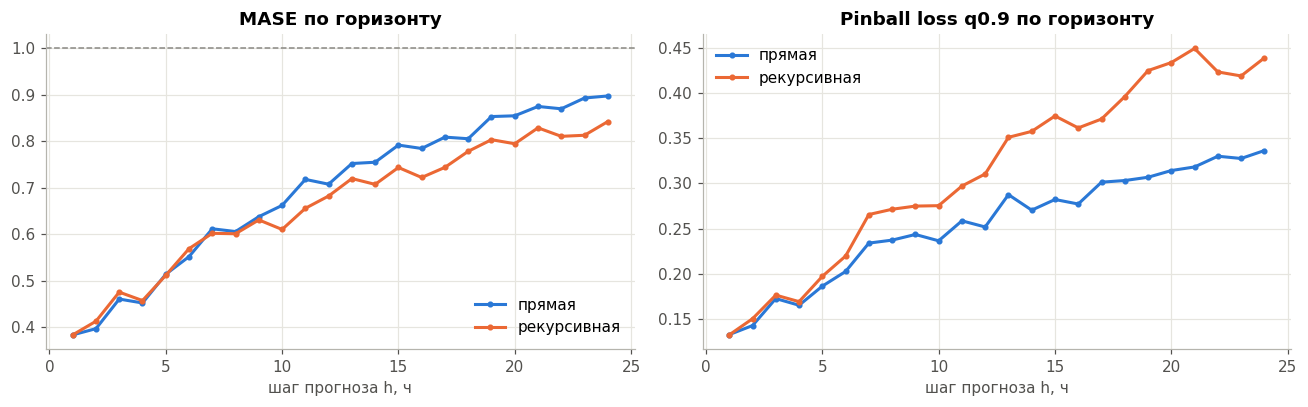

In [77]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(hm_direct.index, hm_direct.MASE, color=COLORS[0], marker='.', label='прямая')
ax[0].plot(hm_rec.index, hm_rec.MASE, color=COLORS[2], marker='.', label='рекурсивная')
ax[0].axhline(1, color='#8a8984', ls='--', lw=1); ax[0].set_xlabel('шаг прогноза h, ч'); ax[0].set_title('MASE по горизонту'); ax[0].legend()
ax[1].plot(hm_direct.index, hm_direct['pinball_q0.9'], color=COLORS[0], marker='.', label='прямая')
ax[1].plot(hm_rec.index, hm_rec['pinball_q0.9'], color=COLORS[2], marker='.', label='рекурсивная')
ax[1].set_xlabel('шаг прогноза h, ч'); ax[1].set_title('Pinball loss q0.9 по горизонту'); ax[1].legend()
plt.tight_layout(); plt.show()

Точечный прогноз: на малых горизонтах стратегии равны (h=1: MAE 0,600 °F, MASE 0,384), на длинных рекурсивная чуть точнее (h=24: MAE 1,318 против 1,404, MASE 0,843 против 0,898; h=12: 1,067 против 1,107). Квантили, нужные решающему слою, у прямой стратегии лучше: на h=24 pinball q0,9 0,336 против 0,439, покрытие q0,9 0,79 против 0,69; на h=6 0,83 против 0,78. У рекурсивной покрытие падает быстрее с ростом горизонта. У обеих покрытие ниже номинальных 0,90: модель обучена только на нормальной работе, интервалы оптимистичны. Стоимость: прямая стратегия это 192 модели (24 горизонта, точка и 7 квантилей), обучение 86,9 с; рекурсивный прогноз 360 точек занял 37,0 с. MASE ниже 1 на всех показанных горизонтах, то есть модель лучше наивного сезонного прогноза. Для решающего слоя выбрана прямая стратегия из-за более честных квантилей.

### 6) **Требования к отчету**:

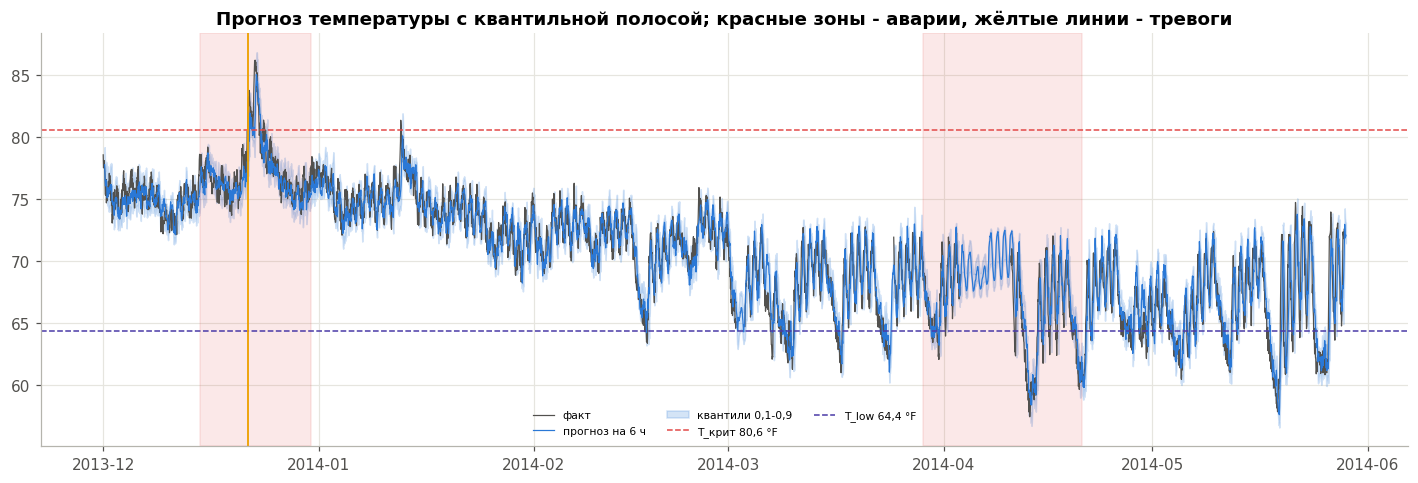

In [78]:
h6 = fc_direct[fc_direct.h == 6].set_index('origin')
h6.index = h6.index + pd.Timedelta(hours=6)
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(nab.index[nab.index >= VAL_START], nab.value[nab.index >= VAL_START], color='#52514e', lw=0.8, label='факт')
ax.plot(h6.index, h6['point'], color=COLORS[0], lw=0.8, label='прогноз на 6 ч')
ax.fill_between(h6.index, h6['q0.1'], h6['q0.9'], color=COLORS[0], alpha=0.2, label='квантили 0,1-0,9')
for a, b in S.FAILURES:
    ax.axvspan(a, b, color=COLORS[5], alpha=0.12)
ax.axhline(T_CRIT, color=COLORS[5], ls='--', lw=1, label='T_крит 80,6 °F')
ax.axhline(T_LOW, color=COLORS[3], ls='--', lw=1, label='T_low 64,4 °F')
for name, lg in logs.items():
    for t in lg.get('time', []):
        ax.axvline(t, color=COLORS[4], lw=1.2)
ax.set_title('Прогноз температуры с квантильной полосой; красные зоны - аварии, жёлтые линии - тревоги'); ax.legend(fontsize=7, ncol=3)
plt.tight_layout(); plt.show()

- **график прогноза с квантильной полосой и отмеченными авариями:** выше;
- **таблица метрик (pinball loss, MASE/MAE по горизонтам, lead time, precision/recall, ложные в день, пропущенные):** пункты 2 и 4;
- **журнал срабатываний: сколько ложных и сколько пропущенных:** пункт 4;
- **вывод о цене ошибки: что дороже в вашем сценарии - ложное отключение или пропущенная авария:** дороже пропущенная авария (в расчёте 50 против 1 за ложную тревогу). Верхнее правило (T > 80,6 °F) на периоде выбора порогов сработало один раз, 21.12.2013 в 20:00, без ложных тревог и пропусков, но это произошло в момент выхода за порог (упреждение 0 ч), а не заранее. На невидимой аварии 2 это правило молчит: пропуск 1 (стоимость 50), потому что температура там не поднималась выше 74,7 °F, а падала (минимум около 57,5 °F). Зеркальное правило для нижнего порога (T < 64,4 °F) её поймало: recall 1,0, за 8 ч до выхода под порог, но 19 тревог, из них 14 ложных (precision 0,26, 0,16 ложных в день); стоимость 14 против 50 за пропуск, при принятых ценах такой компромисс оправдан. Параметры нижнего правила отдельно не подбирались, а взяты у верхнего, а проверочная авария всего одна, поэтому оценка грубая.

## Автоматические проверки

In [79]:
# Проверка 1: Feature Store обеспечивает согласованность
uid = int(snap_users.iloc[0])
fs_features = get_features_from_store([uid]).set_index('user_id').loc[uid, D.USER_FEATURES].to_numpy(float)
direct_features = np.array([calculate_features_directly(uid)[c] for c in D.USER_FEATURES])
assert np.allclose(fs_features, direct_features), 'Feature mismatch!'
feature_match_passed = FEATURE_MATCH_TEST_PASSED and bool(np.allclose(fs_features, direct_features))

# Проверка 2: Data drift обнаруживается
drift_score = DATA_DRIFT_SCORE
assert drift_score < 0.3, 'Data drift превысил порог'

# Проверка 3: Модель соответствует требованиям
latency = INFERENCE_LATENCY_MS
assert latency < 50, f'Latency {latency} ms > 50 ms'

pt = subprocess.run([sys.executable, '-m', 'pytest', '-q', '--color=no', 'tests', '-p', 'no:cacheprovider'], capture_output=True, text=True)
print('pytest:', [l for l in pt.stdout.splitlines() if 'passed' in l or 'failed' in l][-1:])

data_drift_score, inference_latency, online_batch_diff, impact = drift_score, latency, ONLINE_BATCH_DIFFERENCE, UNIQUE_REQUIREMENT_IMPACT
print(f"## METRICS ##")
print(f"FEATURE_MATCH_TEST_PASSED={feature_match_passed}")
print(f"DATA_DRIFT_SCORE={data_drift_score:.4f}")
print(f"INFERENCE_LATENCY_MS={inference_latency:.2f}")
print(f"ONLINE_BATCH_DIFFERENCE={online_batch_diff:.4f}")
print(f"UNIQUE_REQUIREMENT_IMPACT={impact:.4f}")

pytest: ['4 passed in 14.28s']
## METRICS ##
FEATURE_MATCH_TEST_PASSED=True
DATA_DRIFT_SCORE=0.0000
INFERENCE_LATENCY_MS=12.35
ONLINE_BATCH_DIFFERENCE=0.0269
UNIQUE_REQUIREMENT_IMPACT=0.1928


`DATA_DRIFT_SCORE` - доля фич с PSI > 0,2 на тестовом дне относительно обучения; `INFERENCE_LATENCY_MS` - медианная задержка запроса `/predict` целиком (HTTP, Feature Store, модель); `ONLINE_BATCH_DIFFERENCE` - AUC пакетной стратегии минус AUC онлайн-стратегии через 24 часа; `UNIQUE_REQUIREMENT_IMPACT` - прирост HitRate@10 холодных пользователей от запасного списка по категории текущего товара вместо глобального топа (изменение AUC ранжировщика на холодных показано отдельно в Части 7).

In [80]:
server.should_exit = True
stop_mlflow()

## Общие выводы

- **Модель.** Выбрана LightGBM: AUC 0,7795 при эвристике 0,7008 (+0,079), p99 одной строки 4,8 мс; случайный лес с тем же качеством в 10 раз медленнее.
- **Feature Store.** Фичи считаются одной функцией и хранятся с временной меткой: выборка Feast совпала с прототипом, online совпал с прямым расчётом и с offline (все три проверки пройдены).
- **Жизненный цикл.** Production получает версия, прошедшая проверку (AUC выше эвристики на 0,02 и p99 < 50 мс): v3 стала `champion`, v4 (только фичи запроса, AUC 0,5764) отклонена.
- **Сервис.** Последовательно p50 12,3 мс, p99 22,7 мс при требовании < 100 мс. Под параллельной нагрузкой задержка растёт (8 потоков: p50 118,6 мс), предел одного процесса около 70 запросов/с. Canary получил 5,3% запросов, shadow-оценки коррелируют с основной моделью на 0,908, битая модель откатывается автоматически (за время обнаружения пострадало 5% запросов).
- **Мониторинг.** Дрейфа данных на 8-9 октября нет (`drift_score` 0, максимальный PSI 0,079), падение AUC 0,010-0,014 ниже порога алерта; сдвиг цен ×1,5 ловится (PSI 9,81). ADWIN сработал 5 раз, но это информационные алерты: AUC по часам сильно шумит.
- **Пакетное и онлайн-обучение.** Пакетное точнее (AUC через 24 ч 0,7871 против 0,7601), онлайн дешевле по CPU и задержке; выбрано пакетное с ежедневным обновлением.
- **Холодный старт.** AUC почти не изменился, зато запасной список по категории поднял HitRate@10 холодных пользователей с 0,0806 до 0,2733; внутримодельную обработку внедрять не стоит.
- **Прогноз сенсора.** Прямая стратегия даёт лучшие квантили, MASE ниже 1. Решающий слой поймал аварию 1, но без упреждения; верхнее правило пропустило аварию 2 (температура падала), нижнее поймало её ценой 14 ложных тревог.
- **Ограничения.** Требование «рост CTR на 10%» офлайн не проверяется (нужен A/B-тест): измерены AUC и HitRate@10. Использована 5% выборка пользователей, 9 дней данных, один тестовый день и одно разбиение, поэтому разницы порядка 0,001 по AUC в пределах шума.